# Исследовательский анализ данных сервиса "Яндекс Афиша" в Python и проверка гипотез

<a id='intro'></a>
## О проекте
Ссылка на дашборд: https://datalens.yandex/3fronxk0q2q8o  
С помощью дашборда можно было увидеть, что с наступлением осени увеличилось количество заказов, однако у средней стоимости был тренд к снижению. Сотрудники продуктовой команды просят провести исследовательский анализ данных в Python, чтобы выявить инсайты об изменении пользовательских предпочтений и популярности событий осенью 2024 года, а также проверить гипотезы о разнице в поведении пользователей с мобильными и стационарными устройствами.

### Содержание
* [О проекте](#intro)
    - [Цели и задачи проекта](#purpose)
    - [Описание данных](#description)
* [Загрузка данных и знакомство с ними](#download)
    - [Промежуточный вывод](#output1)
* [Предобработка данных и подготовка их к исследованию](#data)
    - [Наличие пропусков в данных](#pass)
    - [Названия, или метки, столбцов датафрейма](#names)
    - [Изучение значений в ключевых столбцах](#meanings)
    - [Преобразование типов данных](#types)
    - [Явные и неявные дубликаты в данных](#dubl)
    - [Создание новых столбцов](#new_columns)
    - [Промежуточный вывод](#output2)
* [Исследовательский анализ данных](#analysis)
    - [Анализ распределения заказов по сегментам и их сезонные изменения](#segments)
    - [Осенняя активность пользователей](#autumn)
    - [Популярные события и партнёры](#events)
    - [Промежуточный вывод](#output3)
* [Статистический анализ данных](#statistic)
* [Итоговый вывод и рекомендации](#output)

<a id='purpose'></a>
### Цели и задачи проекта
Целью проекта является выполнение исследовательского анализа данных сервиса "Яндекс Афиша" для выявления инсайтов об изменении пользовательских предпочтений и популярности событий осени 2024 года.   
Для достижения цели необходимо выполнить следующие задачи:  
* Загрузить данные и ознакомиться с ними.  
* Выполнить предпобработку данных:
  - Проверить данные на наличие пропусков;
  - Изучить названия, или метки, столбцов датафрейма;
  - Изучить значения в ключевых столбцах;
  - Проверить данные на явные и неявные дубликаты.
  - Определить типы данных и при необходимости преобразовать их;
  - Создать несколько новых столбцов.
* Провести исследовательский анализ:
  - Анализ распределения заказов по сегментам и их сезонные изменения.
  - Осенняя активность пользователей.
  - Популярные события и партнёры.
* Провести статистический анализ данных
* Сделать итоговый вывод

<a id='description'></a>
### Описание данных
В нашем распоряжении данные о бронировании билетов на сервисе Яндекс Афиша за период с 1 июня по 30 октября 2024 года.   

Первый датасет `final_tickets_orders_df.csv` включает информацию обо всех заказах билетов, совершённых с двух типов устройств — мобильных и стационарных. Поля датасета соответствуют таблице `purchases`.  
`order_id` — уникальный идентификатор заказа.  
`user_id` — уникальный идентификатор пользователя.  
`created_dt_msk` — дата создания заказа (московское время).  
`created_ts_msk` — дата и время создания заказа (московское время).  
`event_id` — идентификатор мероприятия из таблицы events.  
`cinema_circuit` — сеть кинотеатров. Если не применимо, то здесь будет значение 'нет'.  
`age_limit` — возрастное ограничение мероприятия.  
`currency_code` — валюта оплаты, например rub для российских рублей.  
`device_type_canonical` — тип устройства, с которого был оформлен заказ, например mobile для мобильных устройств, desktop для стационарных.  
`revenue` — выручка от заказа.  
`service_name` — название билетного оператора.  
`tickets_count` — количество купленных билетов.  
`total` — общая сумма заказа.  

Второй датасет `final_tickets_events_df` содержит информацию о событиях, включая город и регион события, а также информацию о площадке проведения мероприятия. Обратите внимание, что из данных исключили фильмы, ведь, как было видно на дашборде, событий такого типа не так много. Датасет содержит такие поля:  
`event_id` — уникальный идентификатор мероприятия.  
`event_name` — название мероприятия. Аналог поля event_name_code из исходной базы данных.  
`event_type_description` — описание типа мероприятия.  
`event_type_main` — основной тип мероприятия: театральная постановка, концерт и так далее.  
`organizers` — организаторы мероприятия.  
`region_name` — название региона.  
`city_name` — название города.  
`venue_id` — уникальный идентификатор площадки.  
`venue_name` — название площадки.  
`venue_address` — адрес площадки.  

Датасет `final_tickets_tenge_df.csv` с информацией о курсе тенге к российскому рублю за 2024 год. Значения в рублях представлено для 100 тенге. Датасет содержит такие поля:  
`nominal` — номинал (100 тенге).  
`data` — дата.  
`curs` — курс тенге к рублю.  
`cdx` — обозначение валюты (kzt).  

<a id='download'></a>
## Загрузка данных и знакомство с ними

In [ ]:
#Установим библиотеки
try:
    import subprocess
    import sys
    
    def install_and_import(package):
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "--upgrade", package])
            print(f"Успешно установлен {package}")
            return __import__(package)
        except subprocess.CalledProcessError:
            print(f"Ошибка установки {package}")
            return None
        except Exception as e:
            print(f"Произошла ошибка: {e}")
            return None

    # Основной список библиотек
    libraries = [
        'matplotlib',
        'numpy==1.23.5',
        'jinja2',
        'seaborn',
        'plotly',
        'missingno',
        'scipy',
        'statsmodels'
    ]

    # Устанавливаем и импортируем основные библиотеки
    for lib in libraries:
        globals()[lib] = install_and_import(lib)

    # Отдельная обработка для phik с возможностью отключения
    try:
        phik = install_and_import('phik')
    except Exception as e:
        print(f"Библиотека phik не найдена: {e}")
        # phik = None  # Если нужно явно указать, что библиотека не доступна

except Exception as e:
    print(f"Критическая ошибка при установке библиотек: {e}")

# Проверка доступности библиотек
print("\nПроверка установленных библиотек:")
for lib in libraries + ['phik']:
    if lib in globals():
        print(f"{lib} доступна")
    else:
        print(f"{lib} НЕ доступна")

# find_peaks является функцией из scipy.signal
from scipy.signal import find_peaks
from scipy import stats

#Импортируем необходимые библиотеки
import pandas as pd
import statsmodels
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import re
import hashlib
import scipy.stats as st

In [2]:
#Загрузим датасет `final_tickets_orders_df.csv` в датафрейм
final_tickets_orders_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_orders_df.csv')

#Загрузим датасет `final_tickets_events_df.csv` в датафрейм
final_tickets_events_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_events_df.csv')

#Загрузим датасет `final_tickets_tenge_df.csv` в датафрейм
final_tickets_tenge_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

In [3]:
# напишем пользовательскую функцию для конвертации валют
def convert_currency(amount, currency, date, exchange_rates):
    currency = currency.lower().strip()
    
    if currency == 'rub':
        return amount
    
    elif currency == 'kzt':
        # Приводим дату к нужному формату
        date_to_search = pd.to_datetime(date)
        
        # Ищем курс на точную дату
        rate = exchange_rates.loc[date_to_search, 'curs']
        
        # Если курс не найден, ищем ближайшую доступную дату
        if pd.isna(rate):
            rate = exchange_rates['curs'].asof(date_to_search)
        
        if pd.notna(rate):
            return amount * rate / 100  # Делим на 100 как в вашем коде
        else:
            print(f"Курс не найден для даты {date}")
            return None
    
    else:
        print(f"Неподдерживаемая валюта: {currency}")
        return None


In [4]:
#Напишем функцию для удаления лишних символов между словами и их склеиванием
def dubl_search(row, columns, axis = None):
    def clean_text(s):
        if pd.isna(s):
            return ''
        s = str(s).lower()
        s = re.sub(r'[\s\.\-\_\(\)\[\]\{\}\,\;\'\"]+', '', s)
        return s
    
   # Собираем очищенные значения
    cleaned_values = []
    for col in columns:
        if col in row:
            cleaned_values.append(clean_text(row[col]))
            
    return cleaned_values

<a id='data'></a>
## Предобработка данных и подготовка их к исследованию

<a id='pass'></a>
### Наличие пропусков в данных

**Датафрейм *final_tickets_orders_df***

In [5]:
#Проверим корректность выгрузки данных из SQL для датафрейма final_tickets_orders_df
tmp0 = final_tickets_orders_df.copy()            # Делаем копию текущего датасета
missing_stats = pd.DataFrame({'Кол-во пропусков': tmp0.isnull().sum(),'Доля пропусков': tmp0.isnull().mean().round(4)})
missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
missing_stats.style.background_gradient(cmap='coolwarm') if not missing_stats.empty else "Пропусков в данных нет"

,Кол-во пропусков,Доля пропусков
days_since_prev,21940,0.075400


По условию: кроме столбца `days_since_prev`, данные не должны содержать пропусков. Эти пропуски ожидаемы и никак не помешают исследованию. Они означают, что клиент сделал пока что один заказ, и времени между заказми нет.  
Вывод: данные из SQL выгружены корректно.

In [6]:
null_days = final_tickets_orders_df[final_tickets_orders_df['days_since_prev'].isnull()]

In [7]:
null_days.sort_values('created_dt_msk')

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,service_name,tickets_count,total,days_since_prev
116739,4145087,561d4ed7a7541a4,2024-06-01,2024-06-01 11:36:18,528263,нет,0,rub,mobile,40.01,Билеты без проблем,2,2000.56,NaN
29486,2730525,0f297636fceff2d,2024-06-01,2024-06-01 14:18:06,525052,нет,0,rub,mobile,6.17,Билеты в руки,1,205.65,NaN
41813,6303180,18ece4c9fe9260a,2024-06-01,2024-06-01 12:53:28,317646,нет,0,rub,mobile,1095.52,Билеты без проблем,4,8427.06,NaN
286775,2715735,fdbf00396927aae,2024-06-01,2024-06-01 21:07:43,421423,нет,6,rub,mobile,870.24,Весь в билетах,3,7911.28,NaN
188225,7948988,9bbe3534bbaa8e1,2024-06-01,2024-06-01 13:30:51,11712,нет,16,rub,mobile,880.50,Городской дом культуры,4,12578.52,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115377,4711747,55055e804bf2cf2,2024-10-31,2024-10-31 10:48:45,549127,нет,16,rub,mobile,54.16,Лови билет!,3,1083.15,NaN
224734,3476173,bc8b2c7e044be5e,2024-10-31,2024-10-31 21:38:39,589957,нет,16,rub,mobile,597.52,Мой билет,2,4267.98,NaN
282693,654183,fbdcd1057d8855f,2024-10-31,2024-10-31 14:01:46,447039,нет,6,rub,mobile,51.60,Лови билет!,3,1289.91,NaN
116801,1992852,562679af25f2179,2024-10-31,2024-10-31 22:03:16,589837,нет,16,rub,desktop,189.22,Мой билет,2,4730.44,NaN


Видим, что пользователей, которые совершили всего 1 заказ (поэтому нет времени между заказами), достаточно много. Выручка с их заказов приносит доход, а даты варьируются от начала до конца исследуемого периода. Таких пользователей нужно внимательней исследовать и провести маркетинговые мероприятия.  
Исключать эти строки в анализе не будем.

**Датафрейм *final_tickets_events_df***

In [8]:
#Проверим корректность выгрузки данных из SQL для датафрейма final_tickets_events_df
tmp1 = final_tickets_events_df.copy() 
missing_stats = pd.DataFrame({'Кол-во пропусков': tmp1.isnull().sum(),'Доля пропусков': tmp1.isnull().mean().round(4)})
missing_stats = missing_stats[missing_stats['Кол-во пропусков'] > 0]
missing_stats.style.background_gradient(cmap='coolwarm') if not missing_stats.empty else "Пропусков в данных нет"

'Пропусков в данных нет'

Вывод: данные из SQL выгружены корректно.

<a id='names'></a>
### Названия, или метки, столбцов датафрейма

**Датафрейм *final_tickets_orders_df***

In [9]:
final_tickets_orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

Названия столбцов соответствуют стилю snake case. Переименование столбцов не требуется.

**Датафрейм *final_tickets_events_df***

In [10]:
final_tickets_events_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


Названия столбцов соответствуют стилю snake case. Переименование столбцов не требуется.

<a id='meanings'></a>
### Изучение значений в ключевых столбцах  
Для категориальных значений изучим, какие категории присутствуют в данных. Проверим, встречаются ли значения, которые могут обозначать пропуски в данных или отсутствие информации. Проведем нормализацию данных, если это необходимо.  

**Датафрейм *final_tickets_orders_df***

Выделим *категориальные* данные:  
* order_id - идентификатор заказа (номинальный тип, используется для классификации/идентификации).	
* user_id - идентификатор пользователя (номинальный тип, служит для классификации клиентов).  
* event_id -  идентификатор события (номинальный тип, классифицирует события).  
* cinema_circuit - сеть кинотеатров (отражает принадлежность к киносети).  
* age_limit — возрастное ограничение мероприятия (имеет фиксированный набор значений).  
* device_type_canonical - тип устройства, с которого был оформлен заказ (имеет фиксированный набор значений).  
* currency_code - валюта оплаты (имеет фиксированный набор значений).  
* service_name - название билетного оператора (имеет фиксированный набор значений).

In [11]:
# order_id представлен в виде числовых значений. Проверим, есть ли исключения
non_numeric = ~final_tickets_orders_df['order_id'].astype(str).str.isdigit()
print("Количество нечисловых значений:", non_numeric.sum())

Количество нечисловых значений: 0


Ранее мы узнали, что пропусков в столбце нет, значений, которые могли бы выступать заглушкой(например, отрицательных), тоже нет.

In [12]:
final_tickets_orders_df['user_id'].unique()

array(['0002849b70a3ce2', '0005ca5e93f2cf4', '000898990054619', ...,
       'fffcd3dde79eb2c', 'fffeeb3c120cf0b', 'ffff00725179321'],
      dtype=object)

Ранее мы узнали, что пропусков в столбце нет, значений, которые могли бы выступать заглушкой(например, отрицательных), тоже нет.

In [13]:
# event_id представлен в виде числовых значений. Проверим, есть ли исключения
non_numeric = ~final_tickets_orders_df['event_id'].astype(str).str.isdigit()
print("Количество нечисловых значений:", non_numeric.sum())

Количество нечисловых значений: 0


Ранее мы узнали, что пропусков в столбце нет, значений, которые могли бы выступать заглушкой(например, отрицательных), тоже нет.

In [14]:
# Изучим значения в столбце cinema_circuit
final_tickets_orders_df['cinema_circuit'].unique()

array(['нет', 'Другое', 'Киномакс', 'КиноСити', 'Москино', 'ЦентрФильм'],
      dtype=object)

В данном столбце пропуски заменены на значение "нет". Это означает, что билет куплен не для сети кинотеатров.

In [15]:
# Изучим значения в столбце age_limit
final_tickets_orders_df['age_limit'].unique()

array([16,  0, 18, 12,  6])

В столбце нет явных заглушек, которые бы обозначали пропуск значения. В России действуют пять категорий: 0+, 6+, 12+, 16+ и 18+. Они и представлены в списке.

In [16]:
final_tickets_orders_df['device_type_canonical'].unique()

array(['mobile', 'desktop'], dtype=object)

Устройства разделены на 2 типа: мобильные устройства и ПК. Заглушек для пропусков нет.

In [17]:
final_tickets_orders_df['currency_code'].unique()

array(['rub', 'kzt'], dtype=object)

Всего 2 валюты: российский рубль и казахстанский тенге. Заглушек для пропусков нет.

In [18]:
final_tickets_orders_df['service_name'].unique()

array(['Край билетов', 'Мой билет', 'За билетом!', 'Лови билет!',
       'Билеты без проблем', 'Облачко', 'Лучшие билеты', 'Прачечная',
       'Быстробилет', 'Дом культуры', 'Весь в билетах', 'Билеты в руки',
       'Тебе билет!', 'Show_ticket', 'Городской дом культуры', 'Яблоко',
       'Билет по телефону', 'Выступления.ру', 'Росбилет',
       'Шоу начинается!', 'Мир касс', 'Восьмёрка', 'Телебилет',
       'Crazy ticket!', 'Реестр', 'Быстрый кассир', 'КарандашРУ',
       'Радио ticket', 'Дырокол', 'Вперёд!', 'Кино билет', 'Цвет и билет',
       'Зе Бест!', 'Тех билет', 'Лимоны', 'Билеты в интернете'],
      dtype=object)

Заглушек для пропусков нет.

**Сначала отсечем строки в датафрейме, которые будут искажать значения для анализа:**  

In [19]:
# 1. Считаем число заказов для каждого event_id
order_counts = final_tickets_orders_df.groupby('event_id')['order_id'].count()


# 2. Выбираем event_id, где число заказов == 1
single_order_event_ids = order_counts[order_counts == 1].index


# 3. Фильтруем исходный датафрейм по этим event_id
single_order_events = final_tickets_orders_df[
    final_tickets_orders_df['event_id'].isin(single_order_event_ids)
]

Выделим из выборки заказы, где выручка ≤ 0. Такие заказы могут искажать средний чек или выручку. Отрицательные значения и нулевая стоимость могут сигнализировать о бесплатных мероприятиях или возвратах. В нашем датафрейме нет флагов о таких событиях, хотя следовало бы их ввести для более глубокого анализа причин и выделения отдельных сегментов данных. 

In [20]:
# Отфильтруем данные, где выручка ≤ 0. Создадим отдельный датасет для таких значений
null_orders_df = final_tickets_orders_df[final_tickets_orders_df['revenue'] <= 0]
print("Процентное отношение заказов с нулевой и отрицательной выручкой:", round(null_orders_df.shape[0] / 
                                                                                final_tickets_orders_df.shape[0] *100, 2), "%")

Процентное отношение заказов с нулевой и отрицательной выручкой: 2.1 %


Примерно 5% данных безопасно для удаления у большинства аналитических задач. У нас - 2.1%. Уберем эти данные, чтобы не искажать показатели.

In [21]:

print("Процентное отношение мероприятий c 1 заказом:", round(single_order_events.shape[0] / 
                                                                                final_tickets_orders_df.shape[0] * 100, 2), "%") 

Процентное отношение мероприятий c 1 заказом: 2.08 %


Мы получили достаточно маленький процент, однако такие заказы могут отражать покупку одним клиентом всех мест на мероприятие. Можно рассмотреть вариант с выделением корпоративных клиентов в отдельный сегмент.

In [22]:
# Получаем event_id из заказов с нулевой/отрицательной выручкой
null_order_ids = null_orders_df['event_id'].unique()

# 4. Исключаем из final_tickets_orders_df
final_tickets_orders_df = final_tickets_orders_df[
    ~final_tickets_orders_df['event_id'].isin(null_order_ids)
].reset_index(drop=True)

In [23]:
final_tickets_orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284731 entries, 0 to 284730
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               284731 non-null  int64  
 1   user_id                284731 non-null  object 
 2   created_dt_msk         284731 non-null  object 
 3   created_ts_msk         284731 non-null  object 
 4   event_id               284731 non-null  int64  
 5   cinema_circuit         284731 non-null  object 
 6   age_limit              284731 non-null  int64  
 7   currency_code          284731 non-null  object 
 8   device_type_canonical  284731 non-null  object 
 9   revenue                284731 non-null  float64
 10  service_name           284731 non-null  object 
 11  tickets_count          284731 non-null  int64  
 12  total                  284731 non-null  float64
 13  days_since_prev        263155 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

Определим **количественные** значения:  
* revenue - выручка от заказа. Представлена в 2 валютах: российский рубль и казахстанский тенге.
* tickets_count - количество купленных билетов.
* total - общая сумма заказа.
* days_since_prev - показывает количество дней между текущим заказом и предыдущим заказом того же клиента.

Для количественных значений посмотрим на распределение и наличие выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха. Для анализа данных важными показателями являются выручка с заказа revenue и количество билетов в заказе tickets_count, поэтому в первую очередь проверьте данные в этих столбцах. Если найдутся выбросы в выручке с заказа revenue, то отберите значения по 99-му процентилю. 

In [24]:
# Разделим датафрейм на 2 части: для рублевого поля и казахтанского тенге. Далее будем использовать эти датафреймы для анализа.
tickets_orders_rub_df = final_tickets_orders_df[final_tickets_orders_df['currency_code'] == 'rub']
tickets_orders_kzt_df = final_tickets_orders_df[final_tickets_orders_df['currency_code'] == 'kzt']

In [25]:
print("=== СТАТИСТИКА ПО RUB ===")
display(tickets_orders_rub_df[['revenue', 'tickets_count', 'total', 'days_since_prev']].describe())

=== СТАТИСТИКА ПО RUB ===


,revenue,tickets_count,total,days_since_prev
count,279668.000000,279668.000000,279668.000000,258960.000000
mean,559.538552,2.758088,6463.512082,3.238056
std,877.185884,1.165831,8659.883954,11.378684
min,0.020000,1.000000,0.930000,0.000000
25%,125.120000,2.000000,2266.042500,0.000000
50%,361.480000,3.000000,4826.050000,0.000000
75%,804.010000,4.000000,8913.920000,1.000000
max,81174.540000,47.000000,811745.400000,148.000000


Приведённые **статистические показатели выручки** говорят о существенной неоднородности данных и возможных особенностях бизнес‑процесса.  
Стандартное отклонение (std): 883,28 руб. — значительная вариативность, есть как очень маленькие, так и крупные заказы.  
Минимальная выручка (min): 0,02 руб. — крайне низкий показатель, возможно, тестовые заказы или ошибки.  
Максимальная выручка (max): 81 174,54 руб. — крупные заказы присутствуют.  
Средняя выручка: 563,35 руб. — относительно невысокая, что может указывать на массовые недорогие заказы.  
Распределение выручки неравномерное, с длинным «хвостом» крупных заказов. Большинство заказов укладываются в диапазон до 810 руб.

На основе представленных статистических данных по выручке (revenue) проведем комплекс анализов. Они дополнят друг друга и дадут полную картину.

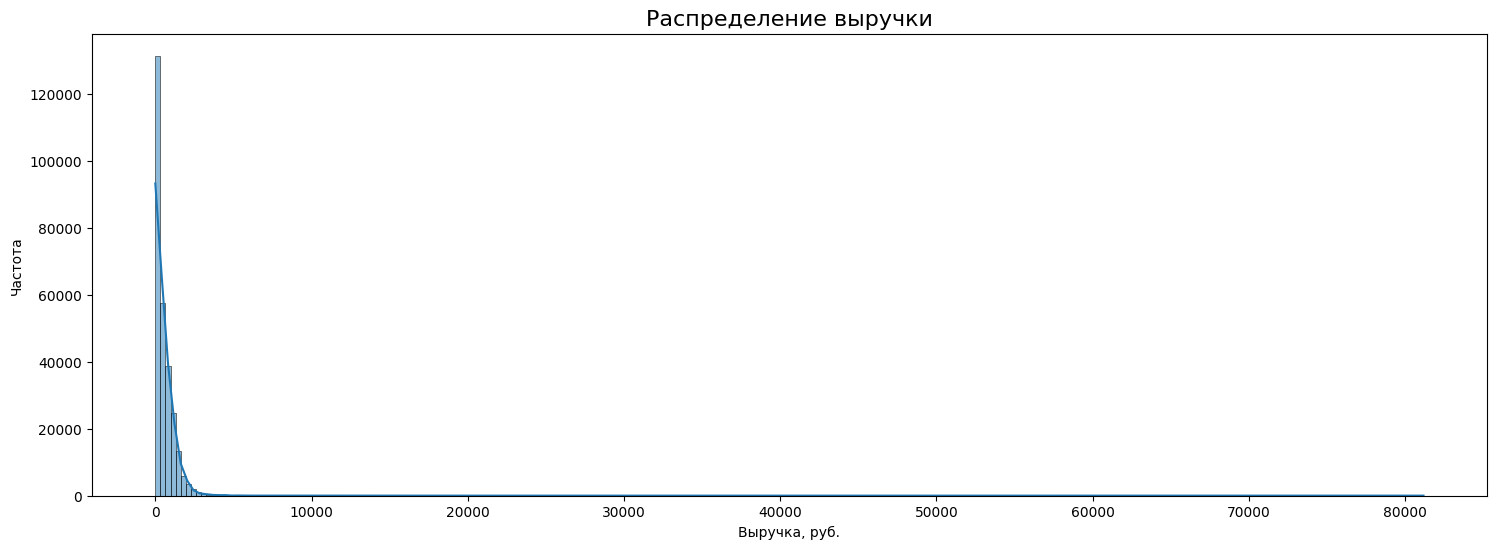

In [26]:
plt.figure(figsize=(18, 6))
# Гистограмма
sns.histplot(tickets_orders_rub_df['revenue'], bins=250, kde=True)
plt.title("Распределение выручки", fontsize=16)
plt.xlabel("Выручка, руб.")
plt.ylabel("Частота")
plt.show()

Гистограмма демонстрирует асимметричное распределение выручки с явным скосом вправо (положительная асимметрия). Основная масса наблюдений сконцентрирована в районе нулевой отметки по оси «Выручка, руб.», а затем наблюдается резкое падение частоты с увеличением выручки.  
* большая часть транзакций имеет низкую выручку (сосредоточена в левом сегменте графика, около 0 руб.);  
* небольшое количество транзакций формирует высокий «хвост» с крупными значениями выручки (правая часть графика);  
* наблюдается экспоненциальный спад частоты транзакций с ростом выручки.

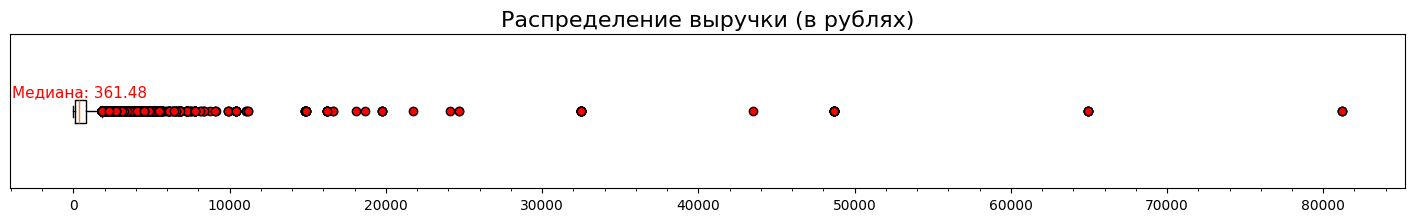

In [27]:
# Для выручки построим ящик с усами
plt.figure(figsize=(18, 2))
plt.gcf().set_facecolor('none')
plt.boxplot(tickets_orders_rub_df['revenue'], vert=False,
        flierprops={  # настройки для выбросов
        'marker': 'o',
        'color': 'red',
        'markerfacecolor': 'red',
        'markersize': 6
    })  

plt.text(
    tickets_orders_rub_df['revenue'].median(), 
    1.1,
    f"Медиана: {tickets_orders_rub_df['revenue'].median():,.2f}",
    ha='center',
    fontsize=11,
    color='red'
)

plt.title('Распределение выручки (в рублях)', fontsize=16)
plt.minorticks_on()
plt.yticks([]) 
plt.show()

Выбросы отображают отдельные значения выручки. Они разбросаны по оси X (выручка в рублях).  
Медиана (365.84): отмечена красным текстом и прямоугольником слева. Это центральное значение выборки — 50% значений ниже, 50% — выше.  
На графике наблюдается:   
* Асимметрия: распределение правостороннее (положительная асимметрия) - большинство значений сконцентрировано слева, а «хвост» распределения уходит вправо (к высоким значениям).  
* Вариативность: большой разброс данных - от низких значений до очень высоких (до 80 000 руб.), что говорит о высокой дисперсии выручки.  
Отсекать значения не будем, так как это может быть признаком отдельного семента пользователей. 

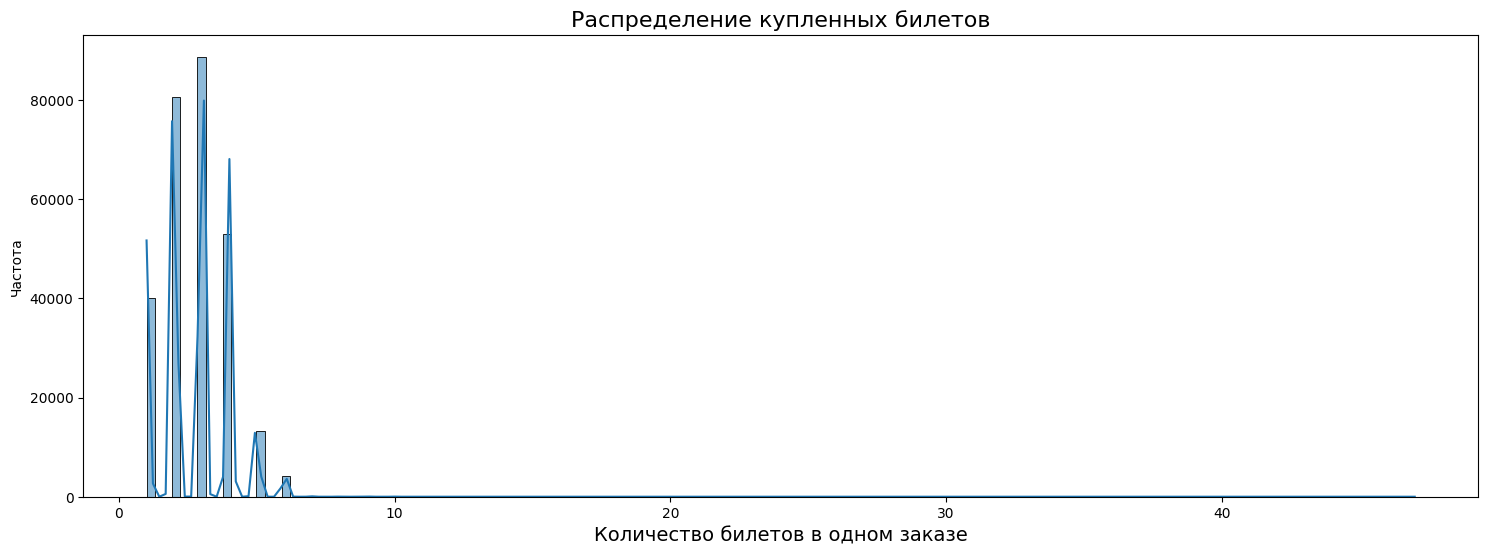

In [28]:
# Изучим распределение количества билетов
plt.figure(figsize=(18, 6))

# Гистограмма
sns.histplot(tickets_orders_rub_df['tickets_count'], bins=150, kde=True)
plt.title("Распределение купленных билетов", fontsize=16)
plt.xlabel("Количество билетов в одном заказе", fontsize=14)
plt.ylabel("Частота")
plt.show()

Распределение асимметрично (левосторонняя асимметрия):
Большая часть заказов сосредоточена на низких значениях (около 0–5 билетов).
Частота резко падает по мере увеличения количества билетов в заказе.  
Это означает, что массовые закупки билетов происходят достаточно редко. Можно рассмотреть маркетинговые кампании в этом направлении. 

In [29]:
most_frequent_tickets = tickets_orders_rub_df['tickets_count'].mode()
print(f"Самое частое количество покупаемых билетов: {most_frequent_tickets[0]}")

Самое частое количество покупаемых билетов: 3


*Теперь выполним анализ для данных, в которых фигурирует валюта тенге.*

In [30]:
print("\n=== СТАТИСТИКА ПО KZT ===")
display(tickets_orders_kzt_df[['revenue', 'tickets_count', 'total', 'days_since_prev']].describe())


=== СТАТИСТИКА ПО KZT ===


,revenue,tickets_count,total,days_since_prev
count,5063.000000,5063.000000,5063.000000,4195.000000
mean,5001.126427,2.763579,75326.130002,4.086532
std,4916.655477,1.115602,68030.177077,13.682304
min,8.670000,1.000000,288.880000,0.000000
25%,518.100000,2.000000,9720.570000,0.000000
50%,3698.830000,3.000000,61647.160000,0.000000
75%,7397.660000,4.000000,114868.830000,1.000000
max,26425.860000,6.000000,344606.500000,147.000000


Среднее значение (mean): 5 008,59 KZT — это средний чек по заказам.
Стандартное отклонение (std): 4 919,20 KZT — высокая вариативность выручки, что говорит о существенных различиях в стоимости заказов.
Минимальное значение (min): 39,44 KZT — крайне низкая выручка, возможно, тестовые заказы или билеты с минимальной ценой.
Максимальное значение (max): 26 425,86 KZT — очень высокая выручка, вероятно, крупные заказы (много билетов или дорогие мероприятия).  
Распределение итогового показателя крайне неравномерное, с большим количеством «выбросов». Медиана (61 647 KZT) даёт более реалистичную картину среднего чека.

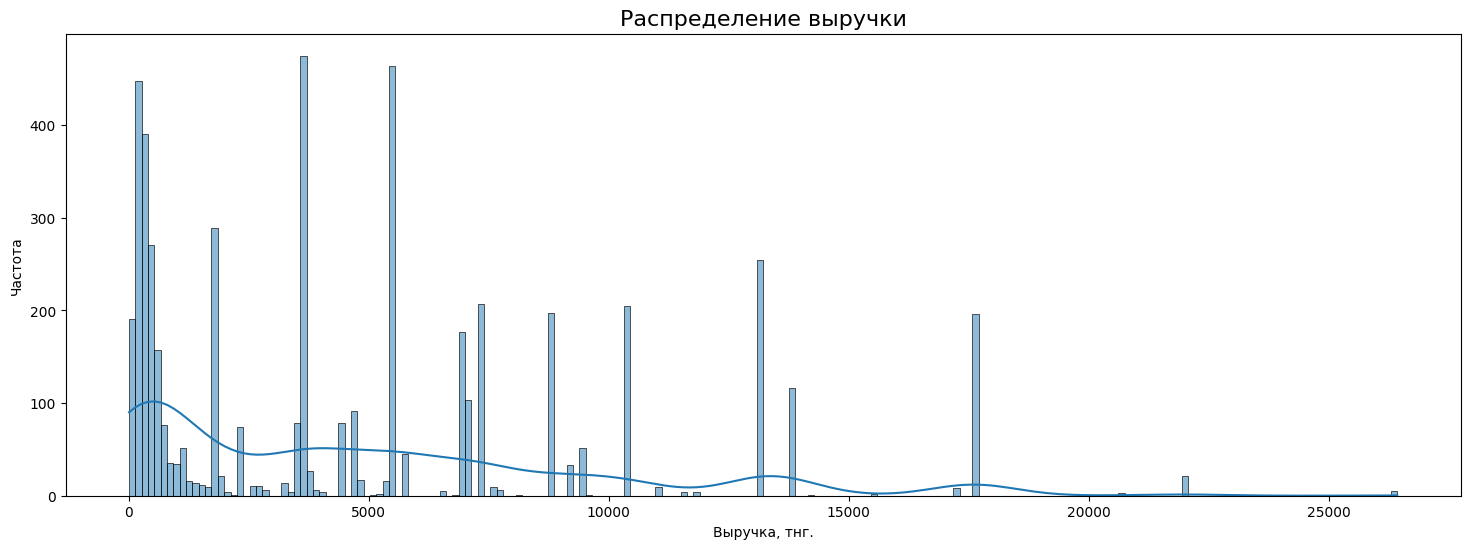

In [31]:
plt.figure(figsize=(18, 6))

# Гистограмма
sns.histplot(tickets_orders_kzt_df['revenue'], bins=200, kde=True)
plt.title("Распределение выручки", fontsize=16)
plt.xlabel("Выручка, тнг.")
plt.ylabel("Частота")
plt.show()

Распределение асимметрично (правосторонняя асимметрия) — «хвост» графика тянется вправо, к большим значениям выручки. Это значит, что хотя большинство значений сосредоточено в нижней части диапазона, есть отдельные случаи с существенно более высокой выручкой.

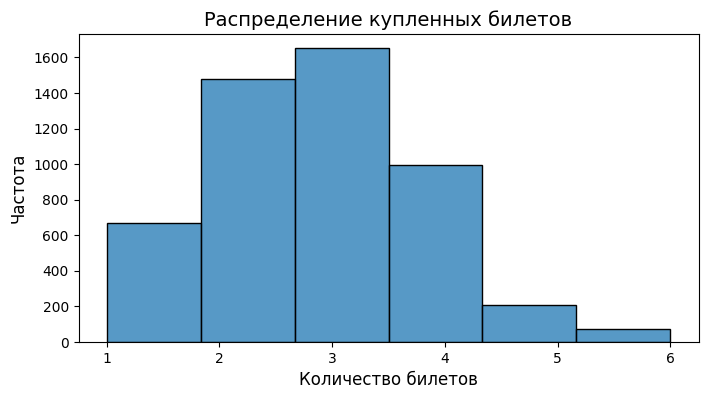

In [32]:
plt.figure(figsize=(8, 4))

# Гистограмма
sns.histplot(tickets_orders_kzt_df['tickets_count'], bins=6)
plt.title("Распределение купленных билетов", fontsize=14)
plt.xlabel("Количество билетов", fontsize=12)
plt.ylabel("Частота", fontsize=12)
plt.show()

Чаще всего одновремененно покупают по 3 билета.

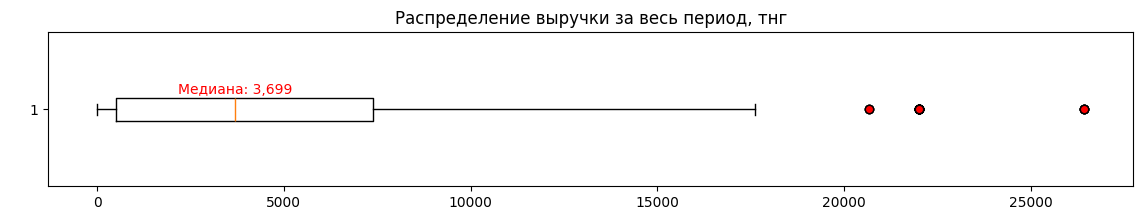

In [33]:
# Для выручки построим ящик с усами
# Создаем простой boxplot
plt.figure(figsize=(14, 2))
plt.boxplot(tickets_orders_kzt_df['revenue'], vert=False,
           flierprops={  # настройки для выбросов
        'marker': 'o',
        'color': 'red',
        'markerfacecolor': 'red',
        'markersize': 6
    })
plt.text(
    tickets_orders_kzt_df['revenue'].median(), 
    1.1,
    f"Медиана: {tickets_orders_kzt_df['revenue'].median():,.0f}",
    ha='center',
    color='red'
)
    
plt.title('Распределение выручки за весь период, тнг')
plt.ylabel(' ')
plt.show()

Медиана (3 699 тнг) — значение, разделяющее данные на две равные части (50% ниже, 50% выше).
Выбросы отмечены отдельными точками (красные точки) справа от основного распределения (около 20–26 тыс. тнг). Это значения, значительно превышающие основной диапазон.
Отсекать выбросы не будем, так как они могут быть признаком VIP-сегмента пользователей.

**Датафрейм *final_tickets_events_df***

Все столбцы в датафрейме являются категориальными данными.

In [34]:
final_tickets_events_df.head()

,event_id,event_name,event_type_description,event_type_main,organizers,region_name,city_name,city_id,venue_id,venue_name,venue_address
0,4436,e4f26fba-da77-4c61-928a-6c3e434d793f,спектакль,театр,№4893,Североярская область,Озёрск,2,1600,"Кладбище искусств ""Проблема"" и партнеры","наб. Загородная, д. 785"
1,5785,5cc08a60-fdea-4186-9bb2-bffc3603fb77,спектакль,театр,№1931,Светополянский округ,Глиноград,54,2196,"Лекции по искусству ""Свет"" Групп","ул. Ягодная, д. 942"
2,8817,8e379a89-3a10-4811-ba06-ec22ebebe989,спектакль,театр,№4896,Североярская область,Озёрск,2,4043,"Кинокомитет ""Золотая"" Инк","ш. Коммуны, д. 92 стр. 6"
3,8849,682e3129-6a32-4952-9d8a-ef7f60d4c247,спектакль,театр,№4960,Каменевский регион,Глиногорск,213,1987,"Выставка ремесел ""Свет"" Лтд","пер. Набережный, д. 35"
4,8850,d6e99176-c77f-4af0-9222-07c571f6c624,спектакль,театр,№4770,Лесодальний край,Родниковец,55,4230,"Фестивальный проект ""Листья"" Групп","пер. Проезжий, д. 9"


In [35]:
final_tickets_events_df['event_type_description'].unique()

array(['спектакль', 'балет', 'мюзикл', 'опера', 'концерт', 'шоу', 'ёлка',
       'цирковое шоу', 'событие', 'фестиваль', 'спортивное мероприятие',
       'выставка', 'спорт', 'оперетта', 'экскурсия', 'рок-мюзикл',
       'музыкальный спектакль', 'снегурочка', 'подарок',
       'кукольный спектакль'], dtype=object)

In [36]:
final_tickets_events_df['event_type_main'].unique()

array(['театр', 'концерты', 'ёлки', 'другое', 'стендап', 'выставки',
       'спорт'], dtype=object)

In [37]:
final_tickets_events_df['organizers'].unique()

array(['№4893', '№1931', '№4896', ..., '№4817', '№5105', '№4552'],
      dtype=object)

In [38]:
np.sort(final_tickets_events_df['region_name'].unique())

array(['Белоярская область', 'Берестовский округ', 'Берёзовская область',
       'Боровлянский край', 'Верховинская область', 'Верхозёрский край',
       'Верхоречная область', 'Ветренский регион', 'Вишнёвский край',
       'Глиногорская область', 'Голубевский округ',
       'Горицветская область', 'Горноземский регион',
       'Горностепной регион', 'Дальнеземская область',
       'Дальнезорский край', 'Дубравная область', 'Залесский край',
       'Заречная область', 'Зеленоградский округ', 'Златопольский округ',
       'Золотоключевской край', 'Зоринский регион', 'Каменевский регион',
       'Каменичская область', 'Каменноозёрный край', 'Каменноярский край',
       'Каменополянский округ', 'Ключеводский округ',
       'Кристаловская область', 'Кристальная область',
       'Крутоводская область', 'Крутоводский регион', 'Лесноярский край',
       'Лесодальний край', 'Лесополянская область', 'Лесостепной край',
       'Лесоярская область', 'Луговая область', 'Лугоградская область',
    

In [39]:
final_tickets_events_df['city_name'].unique()

array(['Озёрск', 'Глиноград', 'Глиногорск', 'Родниковец', 'Радужсвет',
       'Радужнополье', 'Горнодолинск', 'Родниковск', 'Луговинск',
       'Озёрчане', 'Светополье', 'Теплоозеро', 'Дальнесветск', 'Лесоярич',
       'Островецк', 'Озёрово', 'Сосновечин', 'Ягодиновка', 'Родниковецк',
       'Глинополье', 'Акбасты', 'Лесоводск', 'Синеводов', 'Ордакент',
       'Крутовинск', 'Шаныртау', 'Дальнозолотск', 'Кристалевск',
       'Вишнёво', 'Тихоярск', 'Сарыжар', 'Радужанов', 'Теплоозёрск',
       'Каменевский', 'Островополь', 'Кенесар', 'Рощино', 'Верховино',
       'Сосновогорец', 'Дальнозерск', 'Солчелуг', 'Дальнополин', 'Кумсай',
       'Каменосветск', 'Речинцево', 'Светогория', 'Поленоозёрово',
       'Поляногорье', 'Дальнесоснов', 'Заречиновка', 'Радужнояр',
       'Каменский', 'Речевинец', 'Ордасай', 'Песковино', 'Медовецк',
       'Акбастау', 'Луговаярово', 'Травяниново', 'Каражол', 'Глиногорь',
       'Дальнесветин', 'Горнополец', 'Травогород', 'Серебрянка',
       'Сосноград', 'Мал

In [40]:
# Проверим, есть ли в столбце city_id значения, которые не состоят из цифр, так как формат задан числовой.
non_numeric = ~final_tickets_events_df['city_id'].astype(str).str.isdigit()
print("Количество нечисловых значений:", non_numeric.sum())

Количество нечисловых значений: 0


In [41]:
# Проверим, есть ли в столбце venue_id значения, которые не состоят из цифр, так как формат задан числовой.
non_numeric = ~final_tickets_events_df['venue_id'].astype(str).str.isdigit()
print("Количество нечисловых значений:", non_numeric.sum())

Количество нечисловых значений: 0


In [42]:
final_tickets_events_df['venue_name'].unique()

array(['Кладбище искусств "Проблема" и партнеры',
       'Лекции по искусству "Свет" Групп', 'Кинокомитет "Золотая" Инк',
       ..., 'Эстрадный театр "Вытяжка" Лимитед',
       'Школа композиции "Окно" Лимитед',
       'Клуб современных танцев "Кофе" Групп'], dtype=object)

In [43]:
final_tickets_events_df['venue_address'].unique()

array(['наб. Загородная, д. 785', 'ул. Ягодная, д. 942',
       'ш. Коммуны, д. 92 стр. 6', ..., 'ул. Гаражная, д. 7 к. 32',
       'алл. Есенина, д. 5/8 к. 2', 'ш. Тупиковое, д. 49 стр. 73'],
      dtype=object)

### Преобразование типов данных

In [44]:
# Приведем поля created_dt_msk и created_ts_msk к типу даты
final_tickets_orders_df['created_dt_msk'] = pd.to_datetime(final_tickets_orders_df['created_dt_msk'])
final_tickets_orders_df['created_ts_msk'] = pd.to_datetime(final_tickets_orders_df['created_ts_msk'])

In [45]:
# Преобразование в категории
categorical_cols = ['user_id', 'order_id', 'event_id', 'age_limit', 'cinema_circuit', 'currency_code', 
                   'device_type_canonical', 'service_name']
final_tickets_orders_df[categorical_cols] = final_tickets_orders_df[categorical_cols].astype('category')

In [46]:
# Проверем возможность снижения размерности количественных данных.
final_tickets_orders_df['tickets_count'] = pd.to_numeric(final_tickets_orders_df['tickets_count'], downcast='integer')
final_tickets_orders_df['revenue'] = pd.to_numeric(final_tickets_orders_df['revenue'], downcast='float')
final_tickets_orders_df['total'] = pd.to_numeric(final_tickets_orders_df['total'], downcast='float')
final_tickets_orders_df['days_since_prev'] = pd.to_numeric(final_tickets_orders_df['days_since_prev'], downcast='float')

Посмотрим, какие теперь типы данных есть в датафрейме.

In [47]:
final_tickets_orders_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284731 entries, 0 to 284730
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   order_id               284731 non-null  category      
 1   user_id                284731 non-null  category      
 2   created_dt_msk         284731 non-null  datetime64[ns]
 3   created_ts_msk         284731 non-null  datetime64[ns]
 4   event_id               284731 non-null  category      
 5   cinema_circuit         284731 non-null  category      
 6   age_limit              284731 non-null  category      
 7   currency_code          284731 non-null  category      
 8   device_type_canonical  284731 non-null  category      
 9   revenue                284731 non-null  float64       
 10  service_name           284731 non-null  category      
 11  tickets_count          284731 non-null  int8          
 12  total                  284731 non-null  floa

Мы смогли уменьшить использование оперативной памяти в столбцах -memory usage: 32.2+ MB memory usage: 24.8 MB.

In [48]:
categorical_cols = ['event_id', 'event_name', 'event_type_main', 'organizers', 
                    'region_name', 'city_name', 'city_id', 'venue_id', 'venue_name']
final_tickets_events_df[categorical_cols] = final_tickets_events_df[categorical_cols].astype('category')

In [49]:
final_tickets_events_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   event_id                22427 non-null  category
 1   event_name              22427 non-null  category
 2   event_type_description  22427 non-null  object  
 3   event_type_main         22427 non-null  category
 4   organizers              22427 non-null  category
 5   region_name             22427 non-null  category
 6   city_name               22427 non-null  category
 7   city_id                 22427 non-null  category
 8   venue_id                22427 non-null  category
 9   venue_name              22427 non-null  category
 10  venue_address           22427 non-null  object  
dtypes: category(9), object(2)
memory usage: 2.5+ MB


<a id='dubl'></a>
### Явные и неявные дубликаты в данных

In [50]:
# Проверка наличия дубликатов
print("Количество явных дубликатов:", final_tickets_orders_df.duplicated().sum())

Количество явных дубликатов: 0


In [51]:
columns_to_check = ['user_id', 'created_ts_msk', 'event_id', 'cinema_circuit', 'age_limit',
                    'currency_code', 'device_type_canonical', 'revenue', 'service_name',
                    'tickets_count', 'total', 'days_since_prev']

In [52]:
# Применим нашу функцию для склеивания
final_tickets_orders_df['cleaned_list'] = final_tickets_orders_df.apply(lambda row: dubl_search(row, columns_to_check), axis=1)
final_tickets_orders_df['cleaned_str'] = final_tickets_orders_df['cleaned_list'].apply(
    lambda x: str(x).strip().lower()
)

# Создание хэша
final_tickets_orders_df['cleaned_hash'] = final_tickets_orders_df['cleaned_str'].apply(
    lambda x: hashlib.md5(x.encode()).hexdigest()
)

In [53]:
# Удаляем дубликаты по хэшу
clean_orders_df = final_tickets_orders_df.drop_duplicates(
    subset=['cleaned_hash']
).reset_index(drop=True)

# Обновление индекса
clean_orders_df = clean_orders_df.reset_index(drop=True)

# Проверка количества строк
print(f"Исходных строк: {len(final_tickets_orders_df)}")
print(f"Удалено строк: {len(final_tickets_orders_df) - len(clean_orders_df)}")
print(f" в %: {round((len(final_tickets_orders_df) - len(clean_orders_df)) / len(final_tickets_orders_df)*100, 2)}")
print(f"Итоговых строк: {len(clean_orders_df)}")

Исходных строк: 284731
Удалено строк: 29
 в %: 0.01
Итоговых строк: 284702


Так как записи полностью дублируются по всем важным показателям, первую строку можно оставить, так как время одинаково вплоть до секунд.

<a id='new_columns'></a>
### Создание новых столбцов

`revenue_rub` — приведите выручку с заказа к единой валюте — российскому рублю. Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю final_tickets_tenge_df.csv за 2024 год. Значения в рублях представлены для 100 тенге.  
`one_ticket_revenue_rub` — рассчитайте выручку с продажи одного билета на мероприятие.  
`month` — выделите месяц оформления заказа в отдельный столбец.  
`season` — создайте столбец с информацией о сезонности, включая такие категории, как: 'лето', 'осень', 'зима', 'весна'.  

In [54]:
final_tickets_tenge_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB


In [55]:
# Подготовка данных
final_tickets_tenge_df.set_index('data', inplace=True) # Установим столбец data индексом для 
final_tickets_tenge_df.index = pd.to_datetime(final_tickets_tenge_df.index)

In [56]:
clean_orders_df.loc[:, 'revenue_rub'] = clean_orders_df.apply(
    lambda row: convert_currency(
        row['revenue'], 
        row['currency_code'], 
        row['created_dt_msk'], 
        final_tickets_tenge_df
    ),
    axis=1
).round(2)

In [57]:
clean_orders_df.loc[:, 'one_ticket_revenue_rub'] = (clean_orders_df['revenue_rub'] / clean_orders_df['tickets_count']).round(2)

In [58]:
clean_orders_df.loc[:,'month'] = clean_orders_df['created_dt_msk'].dt.month

In [59]:
#Создадим столбец season
seasons = {1 : 'зима',
           2: 'зима',
           3: 'весна',
           4: 'весна',
           5: 'весна',
           6: 'лето',
           7: 'лето',
           8: 'лето',
           9: 'осень',
           10: 'осень',
           11: 'осень',
           12: 'зима'        
}
clean_orders_df.loc[:,'season'] = clean_orders_df['month'].map(seasons)

In [60]:
# Ознакомимся с итоговым датасетом после создания столбцов
clean_orders_df.head()

,order_id,user_id,created_dt_msk,created_ts_msk,event_id,cinema_circuit,age_limit,currency_code,device_type_canonical,revenue,...,tickets_count,total,days_since_prev,cleaned_list,cleaned_str,cleaned_hash,revenue_rub,one_ticket_revenue_rub,month,season
0,4359165,0002849b70a3ce2,2024-08-20,2024-08-20 16:08:03,169230,нет,16,rub,mobile,1521.94,...,4,10870.99,NaN,"[0002849b70a3ce2, 2024082016:08:03, 169230, не...","['0002849b70a3ce2', '2024082016:08:03', '16923...",c6902d182d9db9fdae9e8a2b12713545,1521.94,380.48,8,лето
1,7965605,0005ca5e93f2cf4,2024-07-23,2024-07-23 18:36:24,237325,нет,0,rub,mobile,289.45,...,2,2067.51,NaN,"[0005ca5e93f2cf4, 2024072318:36:24, 237325, не...","['0005ca5e93f2cf4', '2024072318:36:24', '23732...",db0817fdc30d7a3c9106412478b2fc18,289.45,144.72,7,лето
2,7292370,0005ca5e93f2cf4,2024-10-06,2024-10-06 13:56:02,578454,нет,0,rub,mobile,1258.57,...,4,13984.16,75.0,"[0005ca5e93f2cf4, 2024100613:56:02, 578454, не...","['0005ca5e93f2cf4', '2024100613:56:02', '57845...",b280c188570e1580c444e9be809c6ad4,1258.57,314.64,10,осень
3,1139875,000898990054619,2024-07-13,2024-07-13 19:40:48,387271,нет,0,rub,mobile,8.49,...,2,212.28,NaN,"[000898990054619, 2024071319:40:48, 387271, не...","['000898990054619', '2024071319:40:48', '38727...",d3d631c444cc0a67b981867e97eb1772,8.49,4.24,7,лето
4,972400,000898990054619,2024-10-04,2024-10-04 22:33:15,509453,нет,18,rub,mobile,1390.41,...,3,10695.43,83.0,"[000898990054619, 2024100422:33:15, 509453, не...","['000898990054619', '2024100422:33:15', '50945...",995ffc98bbaba62e7bb788c2ec9635ec,1390.41,463.47,10,осень


### Промежуточный вывод

В разделе предобработки данных мы выполнили изменения в датасетах:
* Убрали строки, где: выручка ≤0; количество заказов на одно мероприятие = 1.   
* Разделили датасет `tickets_orders_df` на 2: для рублевой валюты и казахстанского тенге и провели анализ выручки и купленных билетов.
* Проверили наличие пропусков: отсутствуют везде, кроме столбца days_since_prev.
* Выявили неявные дубликаты. Всего неявных дубликатов: 29. 
* Преобразовали типы данных.   

* Собрали в единый датафрейм `orders_df` данные для разных валют и объединили с датафреймом `final_tickets_events_df`.
* Выявили неявные дубликаты и создали новый датафрейм `clean_orders_df`
* Создали 4 новых столбца: `revenue_rub`, `one_ticket_revenue_rub`, `month`, `season`.  
Результаты анализа:

Названия столбцов итогового датафрейма соответствуют стилю snake case.  
Самое частое количество покупаемых билетов: 3.  
В начальном датасете было 290849 строк, оно сократилось до 284702. Разница составляет: 12 119 строк (≈2.11% от исходного объема). Потеря 2.11% данных не критична.

<a id='analysis'></a>
## Исследовательский анализ данных

### Анализ распределения заказов по сегментам и их сезонные изменения

Изучим изменение пользовательской активности или пользовательского интереса в связи с сезонностью. Проанализируем динамику по таким разрезам:  
* тип мероприятия event_type_main;
* тип устройства device_type_canonical;
* категория мероприятий по возрастному рейтингу age_limit.

In [61]:
# Объединим датафреймы по общему столбцу event_id
df = clean_orders_df.merge(final_tickets_events_df, how = 'left', on='event_id')

**Для каждого месяца найдем количество заказов и визуализируем результаты.**

In [62]:
# 4. Анализ по месяцам
monthly_orders = df.groupby('created_dt_msk').agg(
    total_orders=('order_id', 'nunique')
).resample('ME').sum()

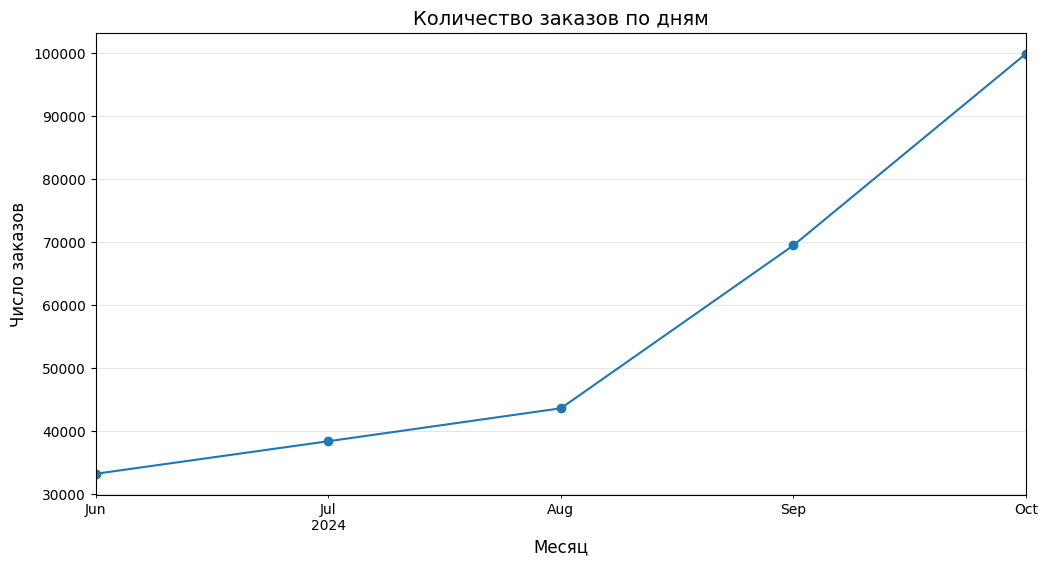

In [63]:
fig = plt.figure(figsize=(12, 6))
ax = fig.add_subplot(111)

# Передали ax в plot()
monthly_orders.plot(kind='line', marker='o', legend=False, ax=ax)  # или kind='bar' для столбцов

# Настройки графика (теперь работают с ax)
ax.set_title('Количество заказов по дням', fontsize = 14)
ax.set_xlabel('Месяц', fontsize = 12)
ax.set_ylabel('Число заказов', fontsize = 12)
ax.grid(True, alpha=0.3)
ax.tick_params(axis='x', rotation=45)  # rotation для xticks через ax

plt.show()

Июнь (Jun): начальное значение — около 30 000 заказов. Это минимальный показатель за рассматриваемый период.  
Июль (Jul): наблюдается небольшой рост — количество заказов увеличивается примерно до 38 000–40 000. Рост умеренный, динамика плавная.  
Август (Aug): происходит заметный скачок — количество заказов достигает примерно 44 000–46 000. Темп роста выше, чем в июле.  
Сентябрь (Sep): резкий рост — количество заказов увеличивается до 70 000. Это второй по значимости этап роста за период.  
Октябрь (Oct): пик активности — количество заказов достигает отметки в 100 000. Это максимальное значение за весь период.  

Общая тенденция: стабильный рост количества заказов с июня по октябрь. График имеет восходящий тренд.
Ускорение роста: наиболее значительный рост наблюдается в период с августа по октябрь. С сентября начинается резкий подъём, что может указывать на определённые факторы, влияющие на увеличение заказов (например, маркетинговые акции, сезонные всплески спроса).

**Для осеннего и летнего периодов сравним распределение заказов билетов по разным категориям:**
* тип мероприятия, 
* тип устройства,
* категория мероприятия по возрастному рейтингу.

In [64]:
# Сгруппируем данные по сезонам и типу мероприятий
season_events = df.groupby(['season', 'event_type_main'], observed=True).agg(
    total_orders=('order_id', 'nunique')  # Уникальные заказы
).reset_index().sort_values('total_orders', ascending=False)


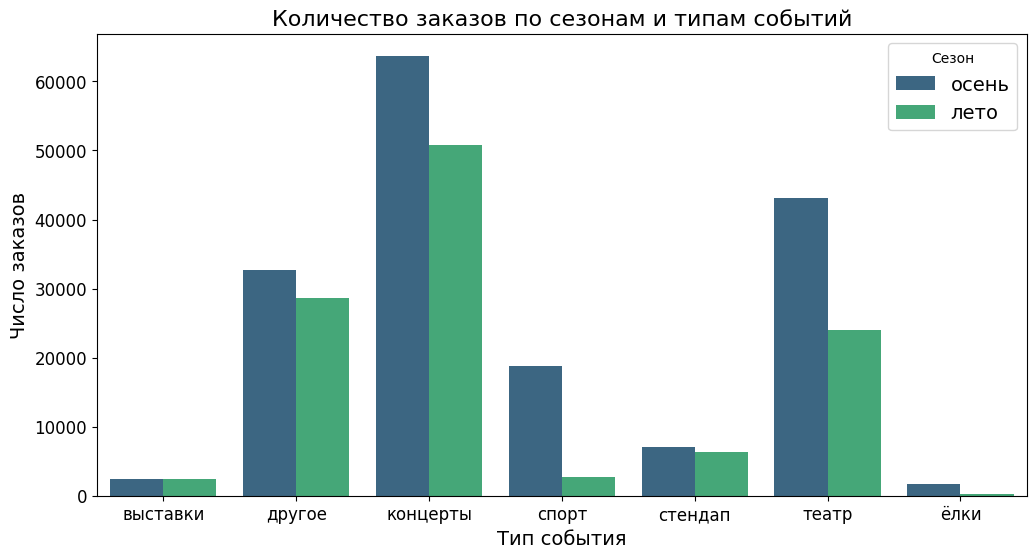

In [65]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=season_events,
    x='event_type_main',
    y='total_orders',
    hue='season',  # сезоны будут разными цветами
    palette='viridis'
)
plt.title('Количество заказов по сезонам и типам событий', fontsize = 16)
plt.xlabel('Тип события', fontsize = 14)
plt.ylabel('Число заказов', fontsize = 14)
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.legend(title='Сезон', fontsize = 14)  # добавим легенду
plt.show()

Лето:
Наибольший объём заказов приходится на концерты (около 50 000 заказов) — это доминирующий тип событий.
Значительный спрос также наблюдается на категорию «другое» (около 28 000 заказов).
Меньшие объёмы — у театра (около 23 000 заказов), стендапа (около 6 000 заказов) и выставок (около 3 000 заказов).
Минимальные значения — у спорта и ёлок (практически отсутствуют).

Осень:
Лидер по заказам — концерты (около 60 000 заказов), что выше, чем в летний период.
Высокие показатели у категории «другое» (около 31 000 заказов) и театра (около 41 000 заказов) — театр становится более востребованным по сравнению с летом.
Средние значения — у спорта (около 19 000 заказов) и стендапа (около 7 000 заказов).
Минимальные значения — у выставок (около 3 000 заказов) и ёлок (около 2 000 заказов).

Анализ по типам событий:  
Концерты — стабильно лидируют в обоих сезонах, причём осенью спрос выше, чем летом. Это указывает на высокую популярность концертов вне зависимости от времени года.  
Театр — значительно увеличивает долю заказов осенью (почти вдвое по сравнению с летом), что может быть связано с началом театрального сезона.  
Категория «другое» — сохраняет стабильно высокие показатели, но немного снижается осенью.  
Выставки — имеют низкие показатели в обоих сезонах (около 3 000 заказов), что может говорить о специфической аудитории или сезонности данного типа событий.  
Спорт — практически отсутствует летом, но осенью набирает около 19 000 заказов, что может быть связано с началом спортивных сезонов.  
Стендап — имеет средние показатели, без резких изменений между сезонами.  
Ёлки — практически отсутствуют летом, а осенью показывают минимальный рост (около 2 000 заказов), что логично, так как ёлки ассоциируются с зимним сезоном.  

In [66]:
# Сгруппируем данные по сезонам и типу устройств
season_devices = df.groupby(['season', 'device_type_canonical'], observed=True).agg(
    total_orders=('order_id', 'nunique')  # Уникальные заказы
).reset_index().sort_values('total_orders', ascending=False)

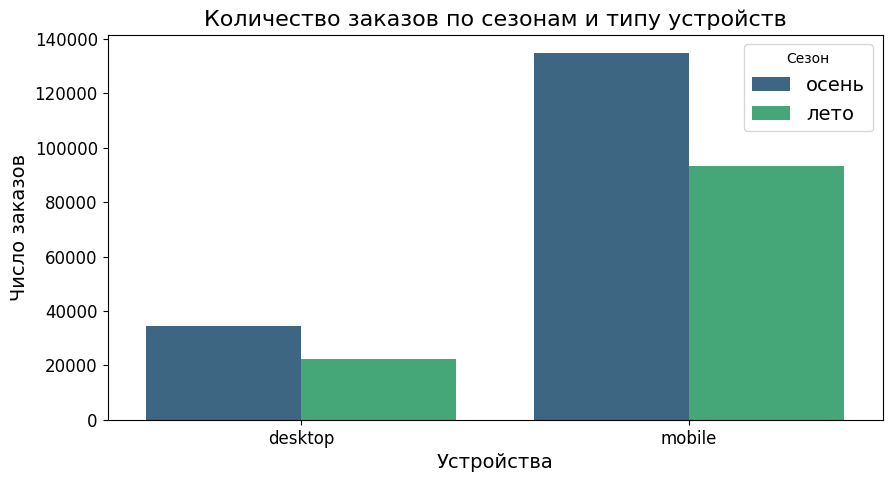

In [67]:
plt.figure(figsize=(10, 5))
sns.barplot(
    data=season_devices,
    x='device_type_canonical',
    y='total_orders',
    hue='season',
    palette='viridis'
)
plt.title('Количество заказов по сезонам и типу устройств', fontsize = 16)
plt.xlabel('Устройства', fontsize = 14)
plt.ylabel('Число заказов', fontsize = 14)
plt.legend(title='Сезон', fontsize = 14)
plt.xticks(fontsize = 12)
plt.yticks(fontsize = 12)
plt.show()

Лето:
desktop: около 20 000 заказов — низкий показатель, что может указывать на меньшую активность пользователей десктопов в этот период.
mobile: около 80 000 заказов — значительно превышает десктопные заказы. Это говорит о том, что летом пользователи чаще используют мобильные устройства для оформления заказов.

Вывод: летом преобладает мобильная активность, вероятно, из-за мобильности пользователей (отпуск, поездки).

Осень:
desktop: около 35 000 заказов — рост по сравнению с летом, но всё ещё ниже мобильных заказов.
mobile: превышает 120 000 заказов — абсолютный лидер по числу заказов среди всех категорий.

Вывод: осенью сохраняется доминирование мобильных устройств, при этом активность десктопов также увеличивается (возможно, связано с началом рабочего/учебного сезона).

In [68]:
# Сгруппируем данные по сезонам и возрастному ограничению
season_age = df.groupby(['season', 'age_limit'], observed=True).agg(
    total_orders=('order_id', 'nunique')
).reset_index().sort_values('total_orders', ascending= False)


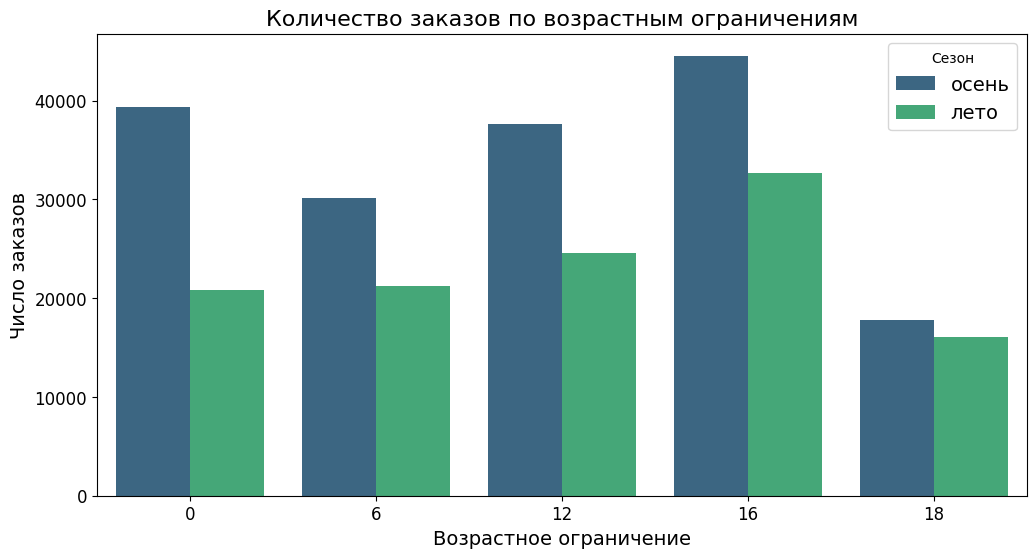

In [69]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=season_age,
    x='age_limit',
    y='total_orders',
    hue='season',  # сезоны будут разными цветами
    palette='viridis'  # выберите палитру на вкус
)
plt.title('Количество заказов по возрастным ограничениям', fontsize = 16)
plt.xlabel('Возрастное ограничение', fontsize = 14)
plt.ylabel('Число заказов', fontsize = 14)
plt.xticks(fontsize = 12) 
plt.yticks(fontsize = 12)
plt.legend(title='Сезон', fontsize = 14)  # добавим легенду
plt.show()

Лето:  
Наибольшее количество заказов приходится на события с возрастным ограничением 16 лет (около 32 тыс. заказов) — это лидирующая категория.  
Далее идут события с ограничением 12 лет (около 24 тыс. заказов).  
События с ограничениями 0 и 6 лет имеют примерно одинаковое количество заказов (около 20 тыс.).  
Наименьшее количество заказов у событий с ограничением 18 лет (около 15 тыс.).  

Осень:  
Лидирует категория с возрастным ограничением 16 лет (более 43 тыс. заказов) — заметный рост по сравнению с летом.
Второе место у событий с ограничением 0 лет (около 38 тыс. заказов) — значительный всплеск интереса.
События с ограничением 12 лет показывают около 37 тыс. заказов.
Категория 6 лет имеет около 29 тыс. заказов.
Наименьшее количество заказов у событий с ограничением 18 лет (около 17 тыс.).

Анализ по возрастным ограничениям:  
0 лет: значительный рост интереса осенью (с незначительного уровня летом до 38 тыс. заказов). Вероятно, это семейные или детские мероприятия, которые более востребованы в осенний период.  
6 лет: стабильный, но не лидирующий спрос в оба сезона (около 20–29 тыс. заказов).  
12 лет: устойчивый интерес летом и осенью (около 24–37 тыс. заказов).  
16 лет: стабильно высокий спрос, лидирующая позиция в обоих сезонах. Это может быть связано с популярностью мероприятий среди подростков и молодёжи.  
18 лет: наименьший спрос в оба сезона (около 15–17 тыс. заказов). Вероятно, такие события менее массовые или ориентированы на узкую аудиторию.  

**Изучим изменение выручки с продажи одного билета в зависимости от типа мероприятия летом и осенью:**

In [70]:
season_one_ticket = df.groupby(['season', 'event_type_main'], observed=True).agg(
    avg_price=('one_ticket_revenue_rub', 'mean')  # Средняя цена билета
).reset_index().sort_values('avg_price', ascending=False)


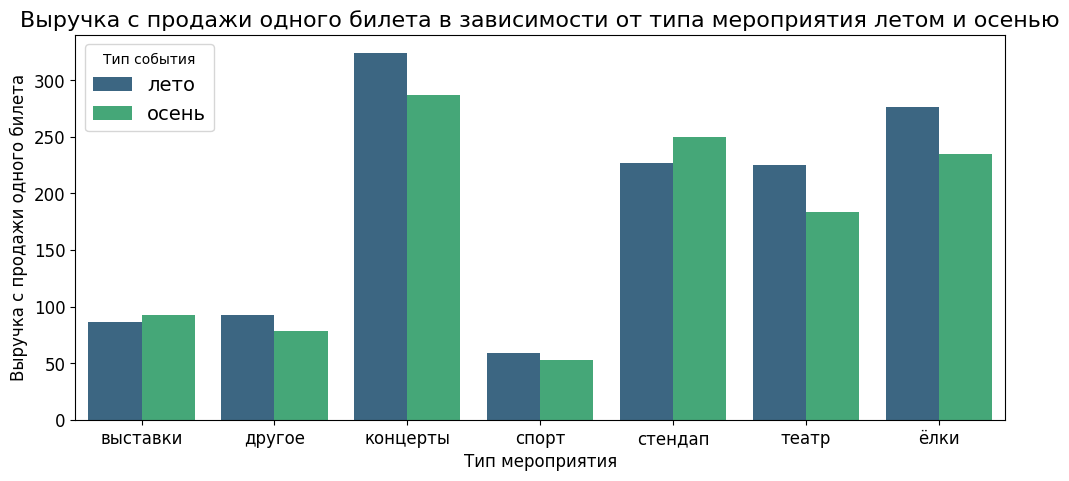

In [71]:
plt.figure(figsize=(12, 5))
sns.barplot(
    data=season_one_ticket,
    x='event_type_main',
    y='avg_price',
    hue='season',
    palette='viridis'
)
plt.title('Выручка с продажи одного билета в зависимости от типа мероприятия летом и осенью', fontsize = 16)
plt.xlabel('Тип мероприятия', fontsize = 12)
plt.ylabel('Выручка с продажи одного билета', fontsize = 12)
plt.legend(title='Тип события', fontsize=14)
plt.xticks(fontsize = 12) 
plt.yticks(fontsize = 12)
plt.show()

Лето:  
Наибольшая выручка — у концертов (около 320 единиц), что делает их лидером по доходности.  
Высокие показатели у «ёлок» (около 280 единиц) и стендапа (около 230 единиц).  
Средний уровень выручки у театра (около 230 единиц).  
Низкая выручка у категорий «другое» (около 90 единиц), «выставки» (около 85 единиц) и «спорт» (около 55 единиц).  

Осень:  
Лидер по выручке — концерты (около 290 единиц), хотя показатель немного ниже, чем летом.  
Высокие значения у стендапа (около 250 единиц) и «ёлок» (около 240 единиц).  
Средний уровень у театра (около 180 единиц) и «другого» (около 95 единиц).  
Низкие показатели у выставок (около 90 единиц) и спорта (около 50 единиц).  

Концерты — стабильно лидируют по выручке в оба сезона, хотя осенью наблюдается небольшое снижение. Это указывает на высокую востребованность и ценовую привлекательность концертов.
Ёлки — демонстрируют стабильно высокую выручку, особенно летом. Вероятно, это связано с предновогодними мероприятиями, которые проходят в конце лета (подготовка, ранние продажи).
Стендап — показывает стабильно высокие результаты (выше среднего), что говорит о растущей популярности этого формата.
Театр — имеет средние показатели, без резких изменений между сезонами. Это может свидетельствовать о стабильной, но не массовой аудитории.
Категория «другое» — демонстрирует невысокую, но стабильную выручку. Требуется анализ состава этой категории для оптимизации доходности.
Выставки — показывают низкие результаты в оба сезона. Возможно, требуется пересмотр ценовой политики или маркетинговой стратегии.
Спорт — имеет наименьшую выручку как летом, так и осенью. Это может быть связано с ограниченным количеством спортивных мероприятий или низкой ценовой категорией билетов.

Летом выручка с билетов в целом выше, чем осенью (особенно заметно по концертам и «ёлкам»).
Осенью наблюдается перераспределение выручки: стендап становится более востребованным, а концерты немного теряют в доходности.
Категории с низкой выручкой («выставки», «спорт») не показывают существенных изменений между сезонами. Сохраняется доминирование мобильных устройств, при этом активность десктопов также увеличивается (возможно, связано с началом рабочего/учебного сезона).

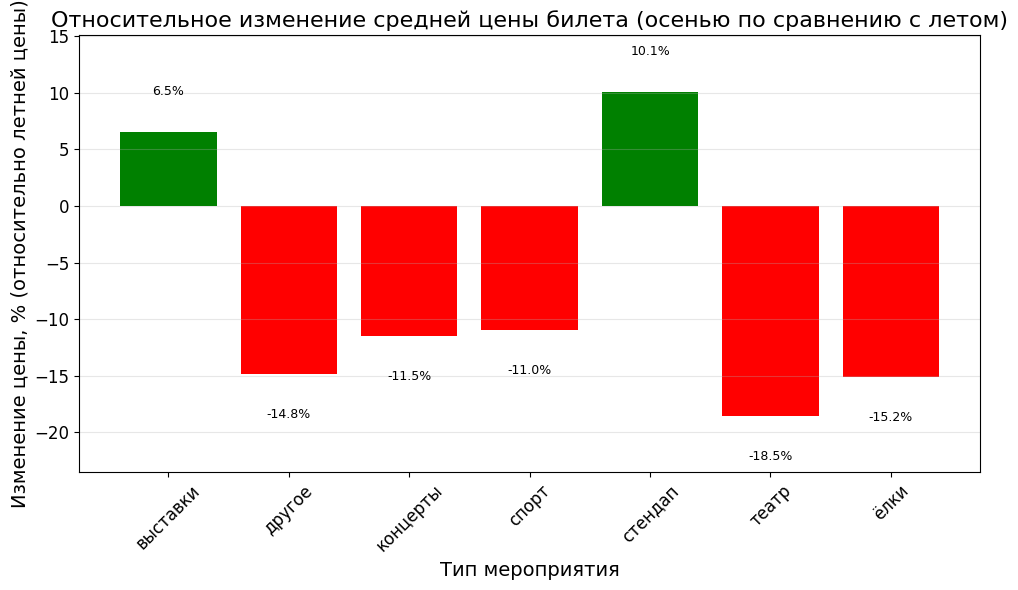

In [72]:
# Получаем средние цены по сезонам
avg_price_autumn = season_one_ticket[season_one_ticket['season'] == 'осень'].set_index('event_type_main')['avg_price']
avg_price_summer = season_one_ticket[season_one_ticket['season'] == 'лето'].set_index('event_type_main')['avg_price']

# Рассчитываем относительное изменение (в процентах от летней цены)
relative_change = ((avg_price_autumn - avg_price_summer) / avg_price_summer * 100).round(2)

# Создаем DataFrame для визуализации
df_relative = pd.DataFrame({
    'event_type_main': relative_change.index,
    'change_percent': relative_change.values  # теперь это отклонение от 100%
})

# Построение графика
fig, ax = plt.subplots(figsize=(10, 6))

# Разделяем столбцы по знаку изменения (выше/ниже нуля)
bars = ax.bar(
    df_relative['event_type_main'],
    df_relative['change_percent'],
    color=['green' if x >= 0 else 'red' for x in df_relative['change_percent']]  # зелёный — рост, красный — падение
)

# Настраиваем ось Y: центр на 0, диапазон с запасом
y_min = min(df_relative['change_percent']) - 5
y_max = max(df_relative['change_percent']) + 5
ax.set_ylim(y_min, y_max)

# Добавляем заголовок и подписи
ax.set_title('Относительное изменение средней цены билета (осенью по сравнению с летом)', fontsize=16)
ax.set_xlabel('Тип мероприятия', fontsize=14)
ax.set_ylabel('Изменение цены, % (относительно летней цены)', fontsize=14)
ax.grid(axis='y', alpha=0.3)

# Добавляем значения на столбцах (с учётом знака)
for bar, value in zip(bars, df_relative['change_percent']):
    height = bar.get_height()
    # Смещение текста зависит от знака значения
    vertical_offset = 3 if height > 0 else -3
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + vertical_offset,
        f'{value:.1f}%',
        ha='center',
        va='bottom' if height > 0 else 'top',  # выравнивание текста
        fontsize=9
    )
plt.xticks(fontsize = 12) 
plt.yticks(fontsize = 12)
# Поворачиваем подписи оси X
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### Промежуточные выводы

Наиболее значительный рост количества заказов наблюдается в период с августа по октябрь. С сентября начинается резкий подъём, что может указывать на определённые факторы, влияющие на увеличение заказов (например, маркетинговые акции, сезонные всплески спроса).  

Концерты — стабильно лидируют по выручке в оба сезона, хотя осенью наблюдается небольшое снижение. Это указывает на высокую востребованность и ценовую привлекательность концертов.  
Ёлки — демонстрируют стабильно высокую выручку, особенно летом. Вероятно, это связано с предновогодними мероприятиями, которые проходят в конце лета (подготовка, ранние продажи).  

Концерты и театр — ключевые направления для привлечения аудитории в летний и осенний периоды. Рекомендуется усилить маркетинговую активность в этих сегментах.  
Выставки и ёлки — менее востребованные направления, возможно, стоит пересмотреть стратегию продвижения или ориентироваться на узкую целевую аудиторию.  
Категория «другое» требует дополнительного анализа, так как включает разнородные события, но стабильно привлекает большое количество заказов.  

Можно заметить рост интереса к семейным мероприятиям осенью: категория «0 лет» демонстрирует значительный рост, что может быть связано с началом учебного года, более свободным графиком у семей или традиционными осенними событиями.  
Стабильность спроса на мероприятия для подростков (16 лет): эта категория лидирует в оба сезона, что указывает на постоянную востребованность среди молодёжи.  
Меньшая популярность мероприятий для совершеннолетних (18 лет): низкий спрос в сравнении с другими категориями может говорить о специфической аудитории или менее активной рекламной кампании.  

Летом выручка с билетов в целом выше, чем осенью (особенно заметно по концертам и «ёлкам»). Преобладает мобильная активность, вероятно, из-за мобильности пользователей (отпуск, поездки).

Осень характеризуется более высоким общим объёмом заказов по всем категориям, что может быть связано с завершением летних отпусков, началом учебного года и традиционными осенними мероприятиями. Растёт спрос на театр и спорт, летом — на концерты и «другое». Это важно учитывать при планировании мероприятий и рекламных кампаний.

<a id='autumn'></a>
### Осенняя активность пользователей

Изучите активность пользователей осенью 2024 года. В вашем распоряжении данные за два осенних месяца. Используйте только эти данные и сделайте следующее:

Проанализируйте динамику изменений по дням для:  
* общего числа заказов;  
* количества активных пользователей DAU;  
* среднего числа заказов на одного пользователя;  
* средней стоимости одного билета.  

In [73]:
autumn_df = df[df['season']=='осень']

In [74]:
# Сгруппируем общее число заказов по дням
autumn_total_orders = autumn_df.groupby('created_dt_msk')['order_id'].agg(
    total_orders='count'
).reset_index()

In [75]:
# Преобразуем дату, оставляя только месяц и день
autumn_total_orders['created_dt'] = autumn_total_orders['created_dt_msk'].dt.strftime('%m-%d')

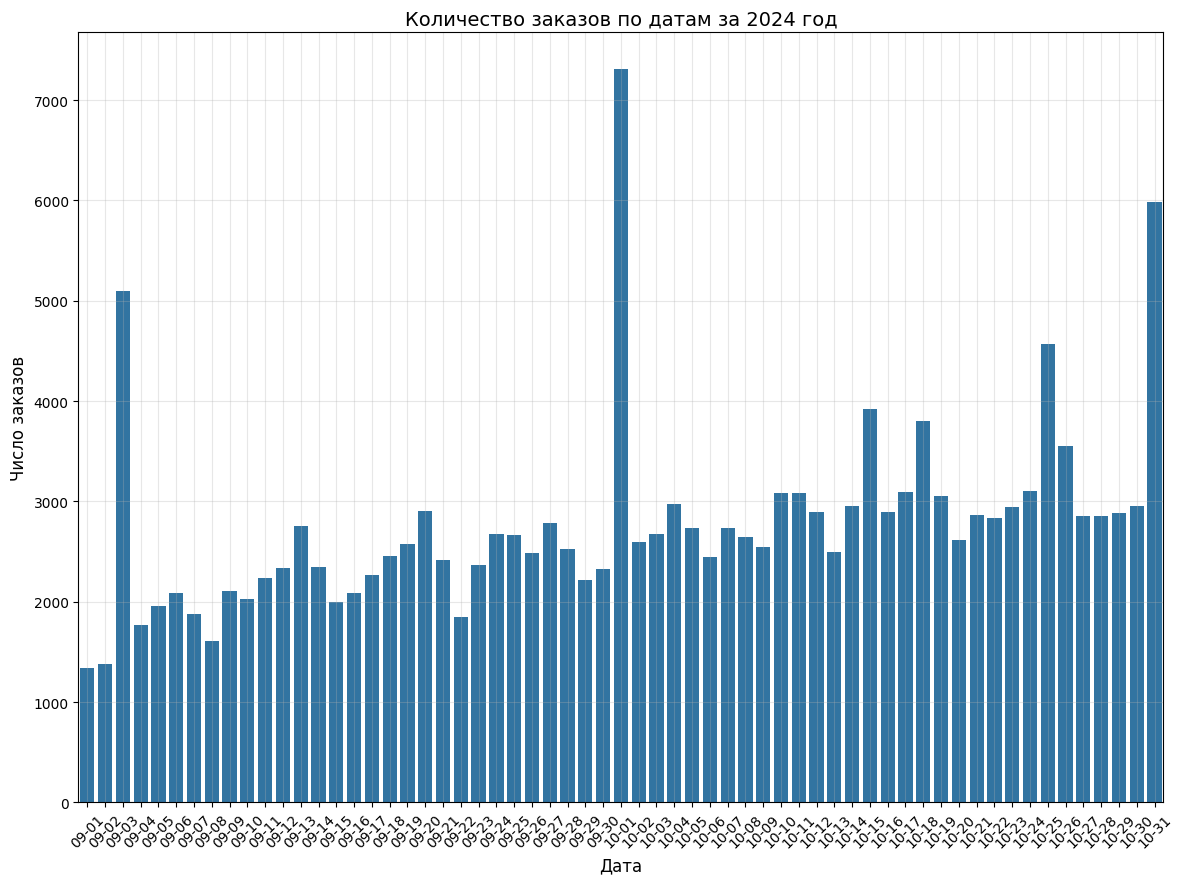

In [76]:
plt.figure(figsize=(14, 10))
sns.barplot(
    data=autumn_total_orders,
    x='created_dt',
    y='total_orders')
plt.title('Количество заказов по датам за 2024 год', fontsize=14)  
plt.xlabel('Дата', fontsize=12)  
plt.ylabel('Число заказов', fontsize=12)  
plt.xticks(rotation=45, fontsize=10)  
plt.yticks(fontsize=10)
plt.grid(True, alpha=0.3)
plt.show()

Диапазон количества заказов: от ~1000 до ~7000 в день.  
Средние значения: большинство дней демонстрируют уровень заказов в диапазоне 2000–3000.  

Пики активности:
Самый высокий пик: около 7000 заказов (заметен в середине периода).  
Другие заметные пики: несколько дней с количеством заказов около 5000 и 4000.  

Периоды спада: некоторые дни показывают снижение до 1000–2000 заказов.

Тенденции и закономерности:
Неравномерность: количество заказов сильно варьируется от дня к дню, что указывает на наличие сезонных или событийных всплесков.
Цикличность: визуально можно заметить повторяющиеся паттерны — периоды роста и спада, возможно связанные с рабочими неделями/выходными или маркетинговыми активностями.

Глобальный тренд: в целом уровень заказов остаётся стабильным (2000–3000), но отдельные всплески указывают на специфические факторы.

Возможные причины пиков и спадов:
Пики (7000, 5000 заказов):
* крупные промоакции или распродажи;
* праздники или предпраздничные дни;
* сезонные всплески спроса (например, начало учебного года, новогодние заказы).

Спады (1000–2000 заказов):
выходные или праздничные дни, когда активность покупателей ниже;
окончание акций, снижение интереса к товарам;
технические или логистические ограничения (например, проблемы с сайтом/доставкой).

In [77]:
# Сгруппируем общее число заказов по пользователям
autumn_total_users = autumn_df.groupby('created_dt_msk')['user_id'].agg(
    DAU='count'
).reset_index()

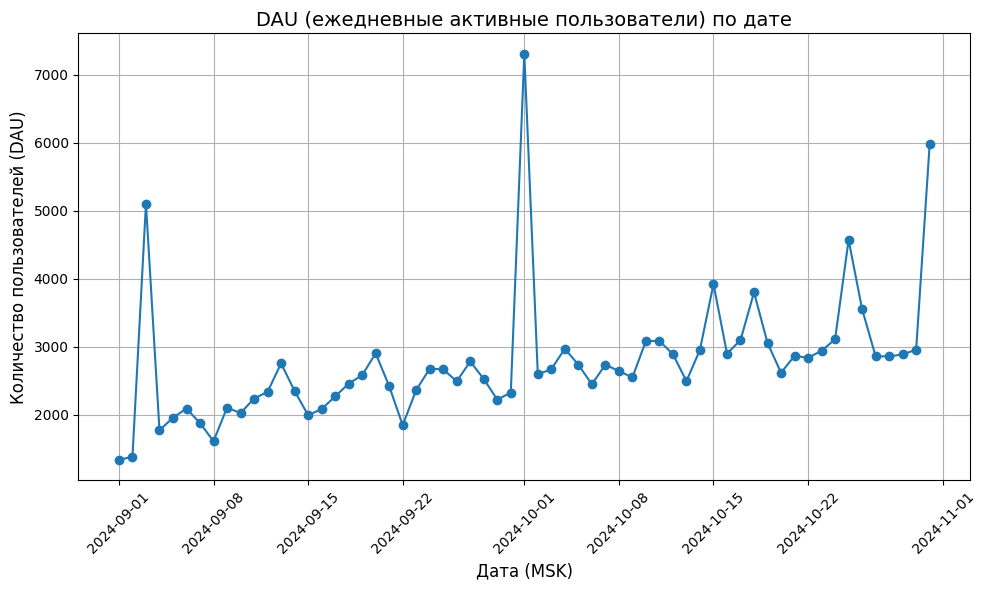

In [78]:
# Количество активных пользователей по дням
plt.figure(figsize=(10, 6))
plt.plot(autumn_total_users['created_dt_msk'], autumn_total_users['DAU'], marker='o')

plt.title('DAU (ежедневные активные пользователи) по дате', fontsize=14)  
plt.xlabel('Дата (MSK)', fontsize=12)  # Размер шрифта подписи оси X
plt.ylabel('Количество пользователей (DAU)', fontsize=12)  
plt.grid(True)
plt.xticks(rotation=45, fontsize=10)  
plt.yticks(fontsize=10)  
plt.tight_layout()
plt.show()

График демонстрирует неравномерную динамику ежедневных активных пользователей (DAU) в период с 2024-09-01 по 2024-11-01. Наблюдаются резкие всплески и спады активности, что указывает на непостоянство пользовательского интереса или влияние внешних факторов.
Ключевые всплески активности

Первый всплеск (около 5000 DAU) — зафиксирован в начале периода (примерно 2024-09-01). Вероятно, связан с запуском акции, новым функционалом или сезонным ростом интереса.  
Самый высокий пик (свыше 7000 DAU) — отмечен около 2024-10-01. Это максимальное значение за весь период.  
Возможные причины:  
* крупные маркетинговые кампании;
* праздничные или тематические события;
* обновление платформы;
* внешние факторы (например, новости, связанные с сервисом).

Второй значительный всплеск (около 6000 DAU) — в районе 2024-11-01. Аналогично может быть связан с акциями, событиями или сезонным ростом.

In [79]:
# Среднее число заказов на одного пользователя по дням
autumn_avg_orders = autumn_df.groupby(['created_dt_msk', 'user_id'], observed=True).agg(
    total_orders=('order_id', 'nunique')         # Общее число заказов
).reset_index()

avg_orders_per_user_per_day = autumn_avg_orders.groupby('created_dt_msk').agg(
    avg_orders=('total_orders', 'mean')  # среднее число заказов на пользователя
).reset_index()

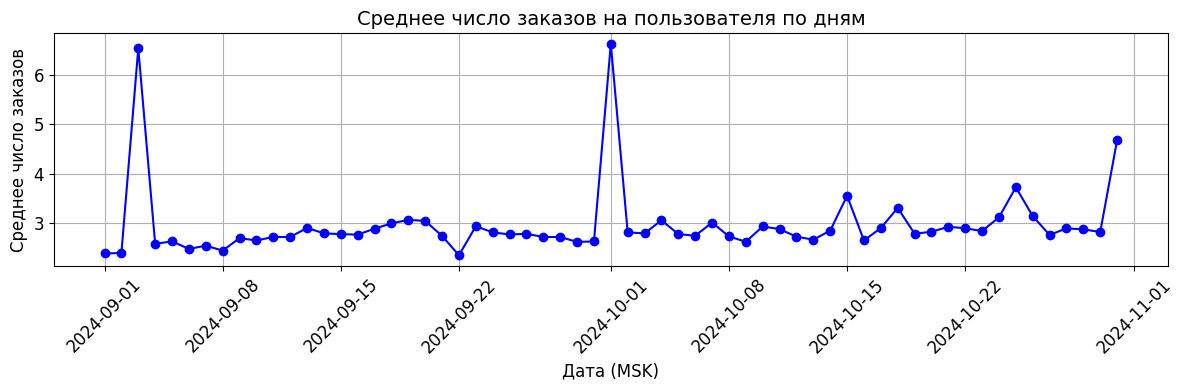

In [80]:
plt.figure(figsize=(12, 4))  # задаём размер графика
plt.plot(avg_orders_per_user_per_day['created_dt_msk'], 
         avg_orders_per_user_per_day['avg_orders'], 
         marker='o',  # добавляем маркеры точек
         linestyle='-',  # тип линии
         color='blue')  # цвет графика

plt.title('Среднее число заказов на пользователя по дням', fontsize=14)
plt.xlabel('Дата (MSK)', fontsize=12)
plt.ylabel('Среднее число заказов', fontsize=12)
plt.grid(True)  # добавляем сетку для удобства чтения
plt.xticks(rotation=45, fontsize=12)  # поворачиваем подписи по оси X для лучшей читаемости
plt.yticks(fontsize=12)
plt.tight_layout()  # корректируем отступы
plt.show()


Базовый уровень активности: основная часть графика находится в диапазоне 2,5–3,5 заказов на пользователя — это можно считать «нормальным» уровнем активности.

Пики активности:
Первый пик: около 6 заказов на пользователя — зафиксирован примерно 1 сентября 2024 г.

Второй пик: также около 6 заказов — наблюдается примерно 1 октября 2024 г.
Третий пик (меньший): около 5 заказов — в районе 1 ноября 2024 г.

Спады: небольшие снижения до уровня 2,5–3 заказов наблюдаются в промежутках между пиками.

Тенденции:
Неравномерность: активность пользователей сильно колеблется — присутствуют резкие всплески и спады.
Цикличность: пиковые значения повторяются примерно с интервалом в месяц, что может указывать на цикличность спроса (например, связанные с акциями, сезонностью или другими событиями).

Общая стабильность: несмотря на пики, основная динамика остаётся в узком диапазоне (2,5–3,5), что говорит о стабильной средней активности.

In [81]:
# Средняя стоимость одного билета за день
autumn_avg_tickets = autumn_df.groupby(['created_dt_msk']).agg(
    total_revenue=('revenue', 'sum'),              # Общая выручка
    total_tickets=('tickets_count', 'sum')       # Общее число билетов
).reset_index()

autumn_avg_tickets['avg_ticket_price'] = autumn_avg_tickets['total_revenue'] / autumn_avg_tickets['total_tickets']

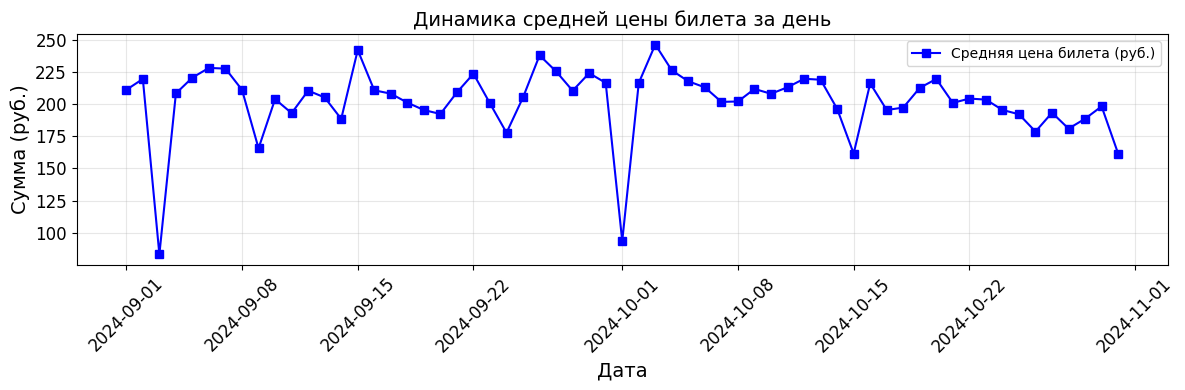

In [82]:
plt.figure(figsize=(12, 4))

# Среднее цена билета
plt.plot(autumn_avg_tickets['created_dt_msk'], autumn_avg_tickets['avg_ticket_price'],
         label='Средняя цена билета (руб.)', color='blue', marker='s')


plt.title('Динамика средней цены билета за день', fontsize=14)
plt.xlabel('Дата', fontsize=14)
plt.ylabel('Сумма (руб.)', fontsize=14)
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45, fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


Диапазон цен: средняя цена колеблется от около 100 руб. (минимальные значения) до 250 руб. (максимальные значения).  

Периоды резких изменений:  
Резкое падение: например, около 2024-09-01 и 2024-10-01, где цена опускается до 100 руб.  
Резкие всплески: несколько дней с ценами около 250 руб. (например, в середине сентября и октябре).  
Общая тенденция: динамика нестабильна, наблюдаются частые колебания.

**Изучим недельную цикличность. Выделим день недели и сравним пользовательскую активность в будни и выходные.**

In [83]:
# Добавляем столбец с днём недели (0 — понедельник, 6 — воскресенье)
autumn_total_users['day_of_week'] = autumn_total_users['created_dt_msk'].dt.dayofweek

# Можно добавить читаемые названия дней
day_names = {0: 'Пн', 1: 'Вт', 2: 'Ср', 3: 'Чт', 4: 'Пт', 5: 'Сб', 6: 'Вс'}
autumn_total_users['day_name'] = autumn_total_users['day_of_week'].map(day_names)

# Создаём столбец «is_weekend» (1 — выходные, 0 — будни)
autumn_total_users['is_weekend'] = autumn_total_users['day_of_week'].isin([5, 6]).astype(int)

In [84]:
# Среднее DAU по дням недели
avg_dau_by_day = autumn_total_users.groupby('day_name')['DAU'].mean().round(2)
print(avg_dau_by_day)

# Среднее DAU для будней и выходных
avg_dau_weekdays = autumn_total_users[autumn_total_users['is_weekend'] == 0]['DAU'].mean()
avg_dau_weekends = autumn_total_users[autumn_total_users['is_weekend'] == 1]['DAU'].mean()

print(f"Среднее DAU в будни: {avg_dau_weekdays:.2f}")
print(f"Среднее DAU в выходные: {avg_dau_weekends:.2f}")

day_name
Вс    2157.00
Вт    3517.78
Пн    2407.11
Пт    3118.25
Сб    2674.50
Ср    2562.00
Чт    3032.89
Name: DAU, dtype: float64
Среднее DAU в будни: 2923.27
Среднее DAU в выходные: 2400.53


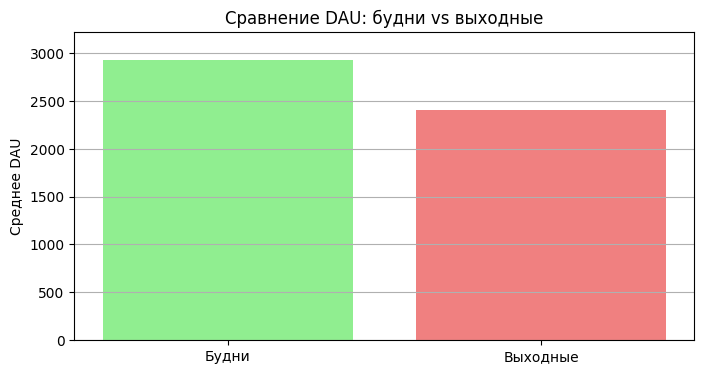

In [85]:
plt.figure(figsize=(8, 4))
data = [avg_dau_weekdays, avg_dau_weekends]
labels = ['Будни', 'Выходные']

plt.bar(labels, data, color=['lightgreen', 'lightcoral'])
plt.title('Сравнение DAU: будни vs выходные')
plt.ylabel('Среднее DAU')
plt.ylim(0, max(data) * 1.1)  # Добавляем небольшой запас сверху
plt.grid(axis='y')
plt.show()

Будни: среднее DAU ≈ 2800–3000 пользователей.  
Выходные: среднее DAU ≈ 2400 пользователей.  

Возможные причины различий:  
Рабочая активность: в будние дни пользователи могут использовать сервис в рамках профессиональных задач (например, корпоративные приложения, рабочие чаты, бизнес-аналитика).  
Досуг в выходные: в выходные пользователи реже обращаются к рабочим/деловым сервисам, предпочитая развлекательные приложения или оффлайн-активности.  
Сезонные или поведенческие факторы: график может отражать общую тенденцию снижения цифровой активности в нерабочие дни.  

<a id='events'></a>
### Популярные события и партнёры

Посмотрим, как события распределены по регионам и партнёрам.

In [86]:
# Распределим события по регионам и посчитаем уникальное количество мероприятий и общее число заказов.
region_analysis = (
    autumn_df.groupby('region_name', observed=True)
    .agg(
        unique_events=('event_id', 'nunique'),
        total_orders=('order_id', 'count'),
        total_revenue=('revenue', 'sum')
    )
    .reset_index()
    .sort_values('total_orders', ascending=False).head(15)
)


In [87]:
region_analysis

,region_name,unique_events,total_orders,total_revenue
23,Каменевский регион,3929,47406,31993105.28
59,Североярская область,2606,20805,12501753.33
41,Медовская область,361,12040,2357273.84
75,Широковская область,794,8669,4294911.07
44,Озернинский край,296,7579,6914089.81
56,Светополянский округ,755,4813,2209036.04
40,Малиновоярский округ,137,4608,3904606.44
60,Серебринская область,456,4477,1592134.78
76,Яблоневская область,431,4220,2017505.50
63,Солнечноземская область,401,4197,873199.29


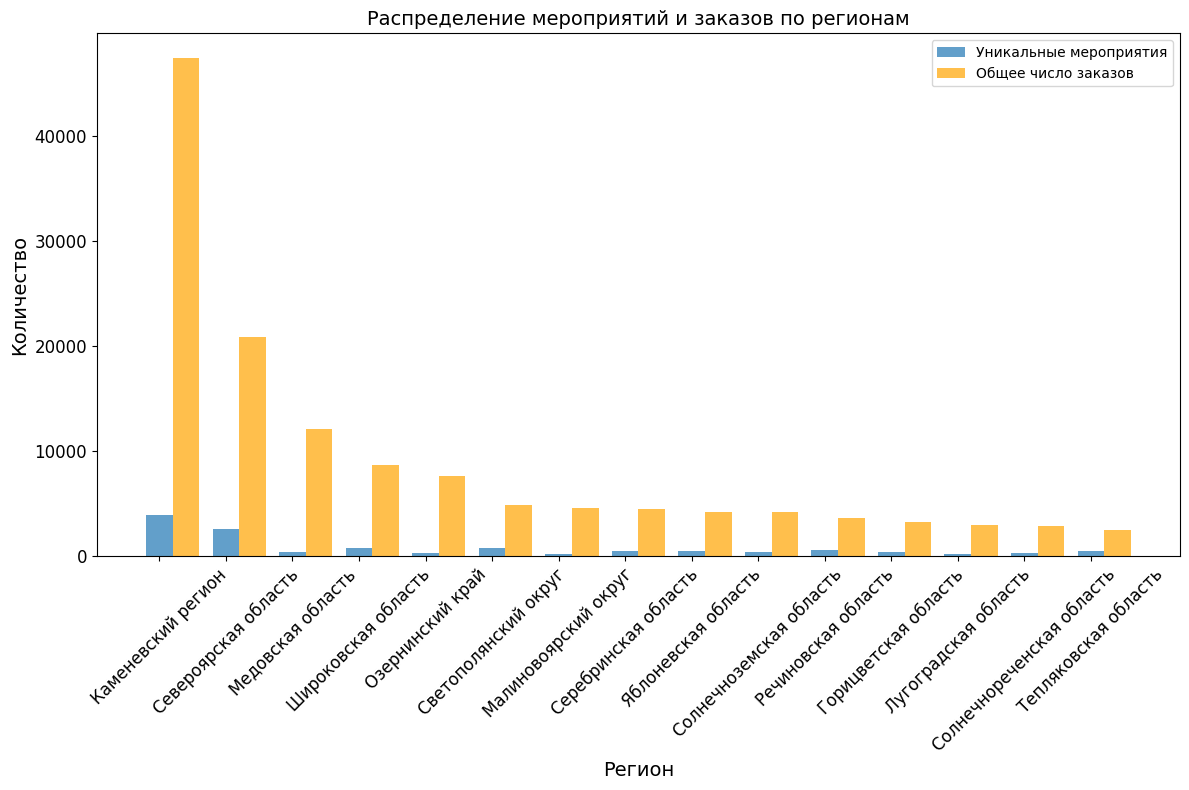

In [88]:
plt.figure(figsize=(12, 8))

# Создаём двойную гистограмму
bars = plt.bar(
    region_analysis['region_name'], 
    region_analysis['unique_events'],
    alpha=0.7,
    label='Уникальные мероприятия',
    width=0.4
)

bars2 = plt.bar(
    [x + 0.4 for x in range(len(region_analysis))],
    region_analysis['total_orders'],
    alpha=0.7,
    label='Общее число заказов',
    width=0.4,
    color='orange'
)

plt.title('Распределение мероприятий и заказов по регионам',fontsize=14)
plt.xlabel('Регион',fontsize=14)
plt.ylabel('Количество',fontsize=14)
plt.legend()
plt.xticks(rotation=45, ha='center',fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


Наибольший объём заказов наблюдается в Каменевском регионе — жёлтая колонка значительно превышает все остальные, достигая отметки свыше 40 000. Это явный лидер по общему числу заказов.

Североярская область занимает второе место по заказам с показателем около 20 000.

Медовская область также выделяется с показателем порядка 10 000 заказов.

Остальные регионы демонстрируют значительно меньшие значения (в диапазоне 5 000 и ниже).

Уникальные мероприятия
Количество уникальных мероприятий (синие столбики) значительно ниже, чем общее число заказов практически во всех регионах.
Наибольшее число уникальных мероприятий также сосредоточено в Каменевском регионе, но показатель существенно меньше, чем по заказам.

В большинстве регионов количество уникальных мероприятий минимально (порядка 1 000 или меньше), что говорит о низкой активности по организации уникальных событий.

Региональные различия  
Лидеры по активности (как по заказам, так и по мероприятиям): Каменевский регион, Североярская и Медовская области.
Регионы с низкой активностью: большинство остальных регионов (например, Малиновоярский округ, Лугоградская область, Тепляковская область) показывают низкие значения как по заказам, так и по мероприятиям.

Дисбаланс между заказами и мероприятиями: в большинстве регионов наблюдается значительный разрыв между общим числом заказов и количеством уникальных мероприятий. Это может указывать на то, что заказы формируются на основе стандартных услуг/действий, а не уникальных событий.

Для каждого билетного партнёра посчитайте общее число уникальных мероприятий, обработанных заказов и суммарную выручку с заказов билетов.

In [89]:
# Распределим события по билетным партнерам и посчитаем уникальное количество мероприятий, обработанных заказов и суммарную выручку с заказов билетов
partner_analysis = (
    autumn_df.groupby('service_name', observed=True)
    .agg(
        unique_events=('event_id', 'nunique'),
        total_orders=('order_id', 'count'),
        total_revenue=('revenue', 'sum')
    )
    .reset_index()
    .sort_values('total_orders', ascending=False).head(15)
)

In [90]:
partner_analysis

,service_name,unique_events,total_orders,total_revenue
3,Билеты без проблем,2829,32411,15044823.17
21,Лови билет!,3594,25786,10644982.78
5,Билеты в руки,2450,25574,7716436.60
24,Мой билет,1013,19682,12595098.84
25,Облачко,1413,15616,12459031.35
22,Лучшие билеты,1377,12370,1742777.00
8,Весь в билетах,608,9642,10170589.26
26,Прачечная,728,5831,2647691.55
30,Тебе билет!,858,3778,2223915.02
34,Яблоко,538,3496,2831861.44


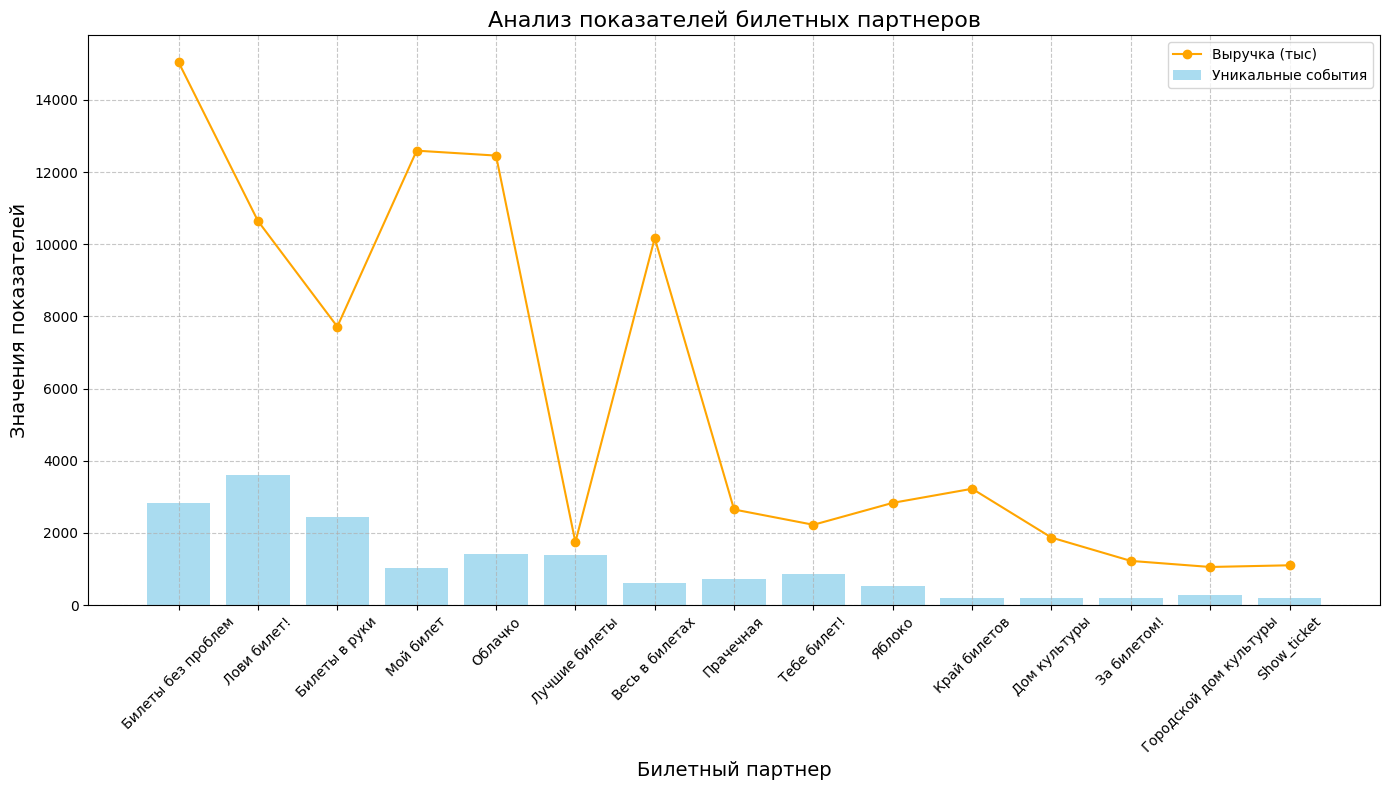

In [91]:
plt.figure(figsize=(14, 8))
plt.bar(
    partner_analysis['service_name'],
    partner_analysis['unique_events'],
    color='skyblue',
    alpha=0.7,
    label='Уникальные события'
)
plt.plot(
    partner_analysis['service_name'],
    partner_analysis['total_revenue'] / 1e3,  # в миллионах
    marker='o',
    linestyle='-',
    color='orange',
    label='Выручка (тыс)'
)
plt.title('Анализ показателей билетных партнеров', fontsize=16)
plt.xlabel('Билетный партнер', fontsize=14)
plt.ylabel('Значения показателей', fontsize=14)
plt.xticks(rotation=45)
plt.legend(loc='best')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Высокая волатильность: выручка сильно колеблется между партнёрами. Например:
Пиковые значения (около 14 000 тыс. руб.) наблюдаются у партнёра «Билеты без проблем».
Значительное падение — у «Облачко» (около 2 000 тыс. руб.).

В конце списка (например, «Городской дом культуры», «Show_ticket») выручка стабильно низкая (около 1 000 тыс. руб.).

Резкие скачки: например, у «Лови билет!» и «Весь в билетах» наблюдаются резкие подъёмы и спады, что может указывать на неравномерность спроса или специфику работы с мероприятиями.

Анализ уникальных событий:
Количество уникальных событий (синие столбцы) значительно ниже по масштабу, чем выручка. Это говорит о том, что объём выручки не всегда прямо пропорционален количеству мероприятий.
Лидеры по количеству событий: «Билеты без проблем», «Лови билет!», «Билеты в руки».
У некоторых партнёров (например, «Яблоко», «Край билетов») количество уникальных событий минимально, что может свидетельствовать о фокусе на высокодоходных, но редких мероприятиях.

Корреляция между выручкой и количеством событий:
У некоторых партнёров (например, «Билеты без проблем») высокая выручка сочетается с относительно большим количеством событий — вероятно, успешная диверсификация по мероприятиям.
У других (например, «Облачко») низкая выручка при небольшом количестве событий — возможно, проблемы с заполняемостью или ценовой политикой.
Есть партнёры с малым числом событий, но относительно высокой выручкой (например, «Лови билет!») — вероятно, работа с премиальными или массовыми мероприятиями.

**Показатели по лидирующим партнерам:** 

| Партнер              | Количество мероприятий |   Сумма |    Выручка |
|-----------------------|-----------------------:|--------:|-----------:|
| Билеты без проблем    | 2829                   |   32411 | 15044823.17 |
| Лови билет!           | 3594                   |   25786 | 10644982.78 |
| Билеты в руки         | 2450                   |   25574 |  7716436.60 |

**Показатели по лидирующим регионам:**

| Регион              | Количество мероприятий |   Сумма |     Выручка |
|----------------------|-----------------------:|--------:|------------:|
| Каменевский регион   | 3929                   |   47406 | 31993105.28 |
| Североярская область | 2606                   |   20805 | 12501753.33 |
| Медовская область    |  361                   |   12040 |  2357273.84 |

### Промежуточный вывод о пользовательской активности и недельной цикличности

Анализ и выводы по данным активности
Основные выводы
Общая динамика показывает стабильную среднюю активность при наличии значительных колебаний. Базовый уровень заказов держится в диапазоне 2000–3000 в день, что свидетельствует о сформировавшейся аудитории.

Пики активности демонстрируют потенциал роста до 7000 заказов, что указывает на:
Эффективное проведение маркетинговых кампаний
Наличие значительного скрытого спроса
Возможность масштабирования при правильном подходе
Сезонные колебания четко прослеживаются в данных:
Будни показывают более высокую активность (2800–3000 DAU)
Выходные демонстрируют снижение до 2400 DAU
Цикличность пиков - примерно месяц

Ключевые проблемы:  
Нестабильность цен в диапазоне 100–250 рублей требует анализа причин
Значительные спады в выходные дни указывают на узкую нишу использования
Зависимость от акций создает риски при их отсутствии

Структура выручки демонстрирует значительную неоднородность:  
Существенный разрыв между лидерами и аутсайдерами (от 14 000 до 1 000 тыс. руб.)
Высокая волатильность у ряда партнеров («Лови билет!», «Весь в билетах»)
Стабильно низкие показатели у части партнеров
Особенности работы с событиями:
Отсутствие прямой корреляции между количеством событий и выручкой.  

Разные стратегии партнеров:  
Диверсификация по количеству мероприятий («Билеты без проблем»)
Фокус на высокодоходных событиях («Яблоко», «Край билетов»)
Смешанная модель («Лови билет!»)

Проблемные зоны  
Ключевые риски:  
Высокая зависимость от отдельных партнеров
Неравномерная загрузка площадок
Возможное неэффективное использование ресурсов у некоторых партнеров
Различия в качестве работы с аудиторией

<a id='statistic'></a>
## Статистический анализ данных

**Проверка гипотезы 1**

Нулевая гипотеза H₀: Среднее количество заказов на пользователя для мобильных устройств не превышает среднего количества заказов на пользователя для стационарных устройств.  
H₀: μmobile ≤ μdesktop  
Альтернативная гипотеза H₁: Среднее количество заказов на пользователя для мобильных устройств строго больше среднего количества заказов на пользователя для стационарных устройств.   
H₁: μmobile > μdesktop 

In [92]:
# подсчёт количества заказов (order_count) для каждого пользователя (user_id) в разрезе типов устройств (device_type_canonical). 
user_device_orders = autumn_df.groupby(
    ['device_type_canonical', 'user_id'], 
    observed=True
).agg(
    order_count=('order_id', 'count')
).reset_index()

In [93]:
# Разделим заказы по типу устройств
mobile_orders = user_device_orders[
    user_device_orders['device_type_canonical'] == 'mobile'
]['order_count'].values  # .values — чтобы получить массив NumPy


desktop_orders = user_device_orders[
    user_device_orders['device_type_canonical'] == 'desktop'
]['order_count'].values

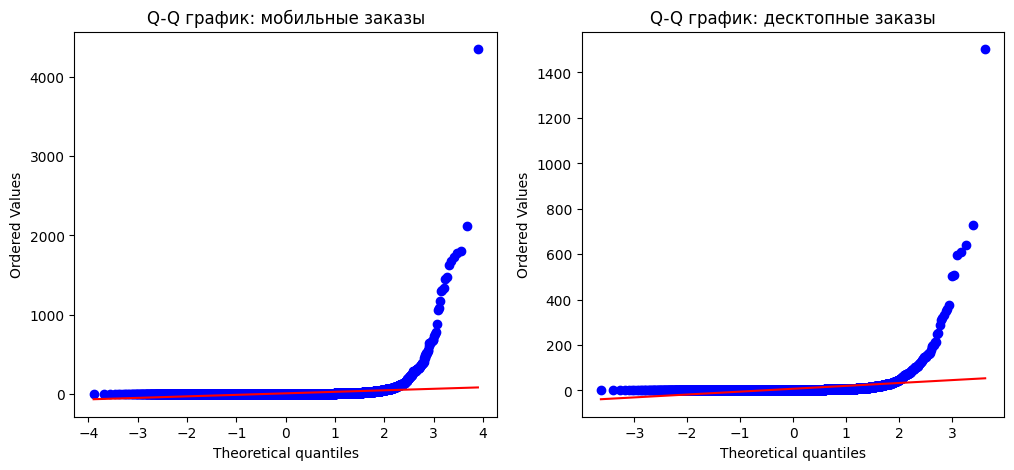

In [94]:
# Проверим распределения на нормальность с помощью Q‑Q графиков
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(mobile_orders, dist="norm", plot=axes[0])
axes[0].set_title('Q-Q график: мобильные заказы')


stats.probplot(desktop_orders, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q график: десктопные заказы')

plt.show()

Оба распределения **не являются нормальными** — присутствуют отклонения в области больших значений (правосторонняя асимметрия).
Мобильные заказы имеют более «тяжёлый хвост», чем десктопные — больше крупных значений/выбросов.

Так как у наших выборок не нормальное распределение будем использовать U‑критерий Манна — Уитни  

In [95]:
# Расчёт среднего количества заказов по типам устройств
avg_by_device = (
    user_device_orders
    .groupby('device_type_canonical', observed=True)['order_count']
    .mean()
    .reset_index()
)
avg_by_device.columns = ['device_type_canonical', 'avg_orders_per_user']

In [96]:
# 1. Выделяем выборки: значения order_count для каждого типа устройства
mobile_sample = avg_by_device.loc[
    avg_by_device['device_type_canonical'] == 'mobile', 
    'avg_orders_per_user'
].values

desktop_sample = avg_by_device.loc[
    avg_by_device['device_type_canonical'] == 'desktop',
    'avg_orders_per_user'
].values

# 3. Выполняем U‑критерий Манна — Уитни
# alternative='greater' означает H₁: mobile > desktop
u_result = st.mannwhitneyu(
    mobile_sample,
    desktop_sample,
    alternative='greater'  # H₁: среднее для mobile > desktop
)

# 4. Выводим результаты
print(f"U‑тест: U={u_result.statistic}, p={u_result.pvalue}")
alpha = 0.05

if u_result.pvalue < alpha:
    print("Отвергаем H₀: среднее для мобильных устройств статистически значимо выше")
else:
    print("Не отвергаем H₀: нет достаточных доказательств, что mobile_avg > desktop_avg")


U‑тест: U=1.0, p=0.5
Не отвергаем H₀: нет достаточных доказательств, что mobile_avg > desktop_avg


Альтернативная гипотеза не подтвердилась. Среднее количество заказов на пользователя для мобильных устройств не превышает среднего количества заказов на пользователя для стационарных устройств.

**Проверка гипотезы 2**

Нулевая гипотеза H₀:  Среднее время между заказами пользователей мобильных приложений не выше по сравнению с пользователями стационарных устройств.  
H₀: μmobile ≤ μdesktop  
Альтернативная гипотеза H₁: Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.  
H₁: μmobile > μdesktop

In [97]:
# Удаляем строки, где days_since_prev имеет NaN
df_clean = df.dropna(subset=['days_since_prev'])

In [98]:
time_between_orders = df_clean.groupby(['device_type_canonical', 'user_id'], observed=True).agg(
    avg_days=('days_since_prev', 'mean')
).reset_index()

In [99]:
mobile_time = time_between_orders[time_between_orders['device_type_canonical'] == 'mobile']['avg_days']
desktop_time = time_between_orders[time_between_orders['device_type_canonical'] == 'desktop']['avg_days']

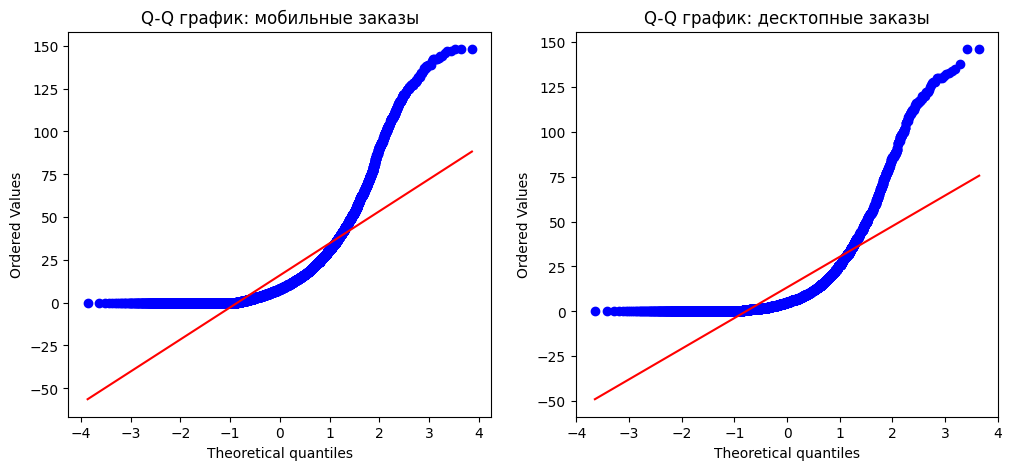

In [100]:
# Проверим распределения на нормальность с помощью Q‑Q графиков
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

stats.probplot(mobile_time, dist="norm", plot=axes[0])
axes[0].set_title('Q-Q график: мобильные заказы')


stats.probplot(desktop_time, dist="norm", plot=axes[1])
axes[1].set_title('Q-Q график: десктопные заказы')

plt.show()

In [101]:
u_result = st.mannwhitneyu(mobile_time, desktop_time, alternative='greater')
print(f"U‑тест: U={u_result.statistic}, p={u_result.pvalue}")
alpha = 0.05

if u_result.pvalue < alpha:
    print("Отвергаем H₀ и принимаем альтернативную гипотезу H₁")
else:
    print("Не отвергаем H₀: нет доказательств, что mobile_avg_time > desktop_avg_time")

U‑тест: U=35424714.0, p=3.592057339183904e-24
Отвергаем H₀ и принимаем альтернативную гипотезу H₁


Среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.

<a id='output'></a>
## Итоговый вывод и рекомендации

В данной работе мы изучили данные за период с  1 июня по 30 октября 2024 года. 
Будни: среднее DAU ≈ 2800–3000 пользователей.  
Выходные: среднее DAU ≈ 2400 пользователей.  

Лето:  
Летом преобладает мобильная активность, вероятно, из-за мобильности пользователей (отпуск, поездки).  
Наибольшее количество заказов приходится на события с возрастным ограничением 16 лет (около 32 тыс. заказов) — это лидирующая категория.
Далее идут события с ограничением 12 лет (около 24 тыс. заказов).
События с ограничениями 0 и 6 лет имеют примерно одинаковое количество заказов (около 20 тыс.).
Наименьшее количество заказов у событий с ограничением 18 лет (около 15 тыс.).

Осень: 
Осенью сохраняется доминирование мобильных устройств, при этом активность десктопов также увеличивается (возможно, связано с началом рабочего/учебного сезона).  
Лидирует категория с возрастным ограничением 16 лет (более 43 тыс. заказов) — заметный рост по сравнению с летом. Второе место у событий с ограничением 0 лет (около 38 тыс. заказов) — значительный всплеск интереса. События с ограничением 12 лет показывают около 37 тыс. заказов. Категория 6 лет имеет около 29 тыс. заказов. Наименьшее количество заказов у событий с ограничением 18 лет (около 17 тыс.).

Анализ по возрастным ограничениям:  
0 лет: значительный рост интереса осенью (с незначительного уровня летом до 38 тыс. заказов). Вероятно, это семейные или детские мероприятия, которые более востребованы в осенний период.   
6 лет: стабильный, но не лидирующий спрос в оба сезона (около 20–29 тыс. заказов).  
12 лет: устойчивый интерес летом и осенью (около 24–37 тыс. заказов).  
16 лет: стабильно высокий спрос, лидирующая позиция в обоих сезонах. Это может быть связано с популярностью мероприятий среди подростков и молодёжи.  
18 лет: наименьший спрос в оба сезона (около 15–17 тыс. заказов). Вероятно, такие события менее массовые или ориентированы на узкую аудиторию.    

Динамика нестабильна, наблюдаются частые колебания всех показателей.  
Возможные причины пиков:  
Промоакции или распродажи (например, начало месяца или специальные предложения).  
Сезонные факторы (например, подготовка к праздникам, начало учебного года).  
Внешние события (например, скидки, запуск новых продуктов/услуг).  
Изменения в маркетинговой стратегии (рассылки, баннеры, push-уведомления).  

Возможные причины спадов:  
Окончание акций — снижение интереса после завершения специальных предложений.  
Выходные/праздничные дни — снижение активности пользователей.  
Технические проблемы или сбои в работе сервиса.  
Усталость аудитории после всплеска активности.  

**Ключевые наблюдения**  
Динамика показателей демонстрирует высокую волатильность с явными пиками и спадами. Основные факторы колебаний:
* Сезонные тренды.
* Маркетинговые активности.
* Технические факторы.
* Праздничные периоды.

*Анализ клиентской базы:*
Структура пользователей характеризуется высокой долей одноразовых клиентов. Требуется:
* Внедрение программ лояльности
* Разработка специальных предложений
* Система напоминаний о новых событиях

**Основные направления оптимизации**  
*Продуктовая стратегия:*  
* Развитие пакетных предложений.  
* Расширение ассортимента мероприятий.  
* Оптимизация ценообразования.  
* Усиление позиций в сегменте концертов.  

*Каналы продаж:*  
* Фокус на мобильные устройства.
* Улучшение UX/UI.
* Развитие мобильных платежей.

*Целевая аудитория:*  
* Акцент на сегмент 16+.  
* Создание молодежных предложений.  
* Развитие комьюнити.  

**Рекомендации по стабилизации**  
*Работа с волатильностью:*  
* Внедрение системы прогнозирования спроса.  
* Планирование маркетинговых активностей.  
* Оптимизация работы в пиковые периоды.

*Ценовая политика:*  
* Разработка гибкой системы скидок.  
* Мониторинг конкурентных цен.  
* Внедрение механизмов стабилизации.  

**Стратегические инициативы**
*Развитие партнерской сети:*
* Внедрение KPI для партнеров.  
* Создание рейтинговой системы.  
* Разработка программ мотивации.  

*Технологические улучшения:*  
* Оптимизация мобильного приложения.  
* Внедрение персонализации.  
* Улучшение процесса покупки.
* Контроль и мониторинг.

*Система отслеживания:*  
* Регулярный анализ ключевых метрик
* Отслеживание эффективности акций
* Мониторинг поведения пользователей

*Управление рисками:*  
* Создание системы раннего предупреждения
* Формирование резервного фонда
* Аудит отстающих партнеров

*Приоритетные задачи:*  
* Внедрение RFM-анализа для сегментации клиентов.  
* Разработка программы лояльности.  
* Оптимизация мобильного приложения.  
* Создание системы прогнозирования спроса.  

Для достижения устойчивого роста необходимо сфокусироваться на работе с клиентской базой, оптимизации процессов и развитии партнерской сети при постоянном мониторинге ключевых показателей.  

Подтвердилась гипотеза о том, что среднее время между заказами пользователей мобильных приложений выше по сравнению с пользователями стационарных устройств.